# Part A: Data cleaning and audit, before/after EDA, driver-race grain, Data-Engineering Q1

**Task.** One row is one driver entering one race. The target is `podium = (positionOrder <= 3)`. Predictors may only use information available **after qualifying and before the race starts**. Raw CSVs are never modified; every cleaning step runs on in-memory copies that are also written to `cleaned_f1/`.

In [6]:
# Setup: imports, configuration, helpers
import os, re, subprocess, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import ParameterGrid
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---- configuration ------------------------------------------------------------------------------
TRAIN_END, VAL_END = 2018, 2021   # chronological split: train <= 2018 | validation 2019-2021 | test 2022+
DROP_ENTITY_IDS = True            # Part B feature-list decision: driverId / constructorId are NOT predictors (see B.1)
OUT_DIR = Path(os.environ.get("F1_OUTPUT_DIR", "cleaned_f1"))
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORT = {}                       # written findings, collected here and assembled into the report at the end of Part D

def section(title):
    display(Markdown(f"#### {title}"))

def record(key, text):
    """Display a written finding and keep it for the final report."""
    REPORT[key] = text
    display(Markdown(text))

def show_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

In [7]:
section("A.1 Load the 14 raw tables (read as strings, never modified)")
TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings", "drivers", "driver_standings",
          "lap_times", "pit_stops", "qualifying", "races", "results", "seasons", "sprint_results", "status"]

def find_data_dir():
    roots = [Path(os.environ["F1_DATASET_DIR"])] if os.environ.get("F1_DATASET_DIR") else []
    for root in roots + [Path("/kaggle/input"), Path.cwd()]:
        for circuits_csv in (sorted(root.rglob("circuits.csv")) if root.exists() else []):
            if all((circuits_csv.parent / f"{t}.csv").exists() for t in TABLES):
                return circuits_csv.parent
    raise FileNotFoundError("Attach the Kaggle 'Formula 1 World Championship' dataset (or set F1_DATASET_DIR).")

DATA_DIR = find_data_dir()
raw = {t: pd.read_csv(DATA_DIR / f"{t}.csv", dtype=str, keep_default_na=False) for t in TABLES}
raw_summary = pd.DataFrame([
    {"table": t, "rows": len(df), "columns": df.shape[1],
     "sentinel_cells": int((df == "\\N").sum().sum()), "blank_cells": int((df == "").sum().sum())}
    for t, df in raw.items()])
print(f"Dataset directory: {DATA_DIR}")
display(raw_summary)

#### A.1 Load the 14 raw tables (read as strings, never modified)

Dataset directory: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020


,table,rows,columns,sentinel_cells,blank_cells
0,circuits,77,9,0,0
1,constructors,212,5,0,0
2,constructor_results,12625,5,12608,0
3,constructor_standings,13391,7,0,0
4,drivers,861,9,1559,0
5,driver_standings,34863,7,0,0
6,lap_times,589081,6,0,0
7,pit_stops,11371,7,0,0
8,qualifying,10494,9,11600,68
9,races,1125,18,11349,0


In [8]:
section("A.2 Cleaned copies: sentinels to NaN, semantic types, durations in seconds")

def to_seconds(value):
    """'1:26.572' -> 86.572; '+5.4' -> 5.4; missing or unparseable -> NaN."""
    if pd.isna(value):
        return np.nan
    try:
        total = 0.0
        for part in str(value).strip().lstrip("+").split(":"):
            total = total * 60 + float(part)
        return total
    except ValueError:
        return np.nan

TEXT_DURATIONS = {"qualifying": ["q1", "q2", "q3"], "pit_stops": ["duration"], "lap_times": ["time"],
                  "results": ["fastestLapTime"], "sprint_results": ["fastestLapTime"]}
MS_TO_SEC = {"lap_times": "lap_time_sec", "pit_stops": "pit_duration_sec",
             "results": "race_time_sec", "sprint_results": "race_time_sec"}

def clean_table(name, df):
    df = df.replace({"\\N": np.nan, "": np.nan})
    for col in df.columns:
        if col == "dob" or col == "date" or col.endswith("_date"):
            df[col] = pd.to_datetime(df[col], errors="coerce")
        else:
            numeric = pd.to_numeric(df[col], errors="coerce")
            if numeric.notna().sum() == df[col].notna().sum():      # every non-missing value parses -> numeric column
                df[col] = numeric
    for col in TEXT_DURATIONS.get(name, []):
        df[f"{col}_sec"] = df[col].map(to_seconds)
    if name in MS_TO_SEC:
        df[MS_TO_SEC[name]] = df["milliseconds"] / 1000.0
    return df

tables = {t: clean_table(t, df) for t, df in raw.items()}
for t, df in tables.items():
    df.to_csv(OUT_DIR / f"{t}.csv", index=False)           # cleaned copies; raw CSVs stay untouched

rs = raw_summary.set_index("table")
cleaning_summary = pd.DataFrame([
    {"table": t, "rows": len(df), "sentinel_or_blank_cells_replaced": int(rs.loc[t, "sentinel_cells"] + rs.loc[t, "blank_cells"]),
     "missing_cells_after": int(df.isna().sum().sum()), "numeric_cols": df.select_dtypes("number").shape[1],
     "datetime_cols": df.select_dtypes("datetime").shape[1], "duplicate_rows": int(df.duplicated().sum())}
    for t, df in tables.items()])
cleaning_summary.to_csv(OUT_DIR / "cleaning_summary.csv", index=False)
display(cleaning_summary)
record("cleaning", "**Cleaning decisions.** Literal `\\N` and blank strings become missing values; a column becomes numeric when every "
       "non-missing value parses as a number; `date`, `*_date` and `dob` become datetimes; qualifying, pit-stop, lap and fastest-lap "
       "durations are converted to seconds (`*_sec`). Raw CSVs are never overwritten; cleaned copies are written to "
       f"`{OUT_DIR}/`.")

#### A.2 Cleaned copies: sentinels to NaN, semantic types, durations in seconds

,table,rows,sentinel_or_blank_cells_replaced,missing_cells_after,numeric_cols,datetime_cols,duplicate_rows
0,circuits,77,0,0,4,0,0
1,constructors,212,0,0,1,0,0
2,constructor_results,12625,12608,12608,4,0,0
3,constructor_standings,13391,0,0,6,0,0
4,drivers,861,1559,1559,2,1,0
5,driver_standings,34863,0,0,6,0,0
6,lap_times,589081,0,0,7,0,0
7,pit_stops,11371,0,0,7,0,0
8,qualifying,10494,11668,23336,9,0,0
9,races,1125,11349,11349,4,6,0


**Cleaning decisions.** Literal `\N` and blank strings become missing values; a column becomes numeric when every non-missing value parses as a number; `date`, `*_date` and `dob` become datetimes; qualifying, pit-stop, lap and fastest-lap durations are converted to seconds (`*_sec`). Raw CSVs are never overwritten; cleaned copies are written to `cleaned_f1/`.

In [9]:
section("A.3 Key audit: primary-key uniqueness / non-nullness and foreign-key reconciliation")
PRIMARY_KEYS = {"circuits": ["circuitId"], "constructors": ["constructorId"], "constructor_results": ["constructorResultsId"],
                "constructor_standings": ["constructorStandingsId"], "drivers": ["driverId"], "driver_standings": ["driverStandingsId"],
                "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"], "qualifying": ["qualifyId"],
                "races": ["raceId"], "results": ["resultId"], "seasons": ["year"], "sprint_results": ["resultId"], "status": ["statusId"]}
FK_PARENTS = {"raceId": "races", "driverId": "drivers", "constructorId": "constructors", "circuitId": "circuits", "statusId": "status"}

pk_audit = pd.DataFrame([
    {"table": t, "primary_key": " + ".join(k), "null_key_rows": int(tables[t][k].isna().any(axis=1).sum()),
     "duplicate_key_rows": int(tables[t].duplicated(k, keep=False).sum())} for t, k in PRIMARY_KEYS.items()])
pk_audit["passes"] = (pk_audit["null_key_rows"] == 0) & (pk_audit["duplicate_key_rows"] == 0)

fk_links = [(c, col, p, col) for c, df in tables.items() for col, p in FK_PARENTS.items() if col in df.columns and c != p]
fk_links.append(("races", "year", "seasons", "year"))
fk_rows = []
for child, col, parent, parent_col in fk_links:
    values = tables[child][col].dropna()
    orphan = ~values.isin(tables[parent][parent_col])
    fk_rows.append({"child": child, "column": col, "parent": parent, "checked_rows": len(values), "orphan_rows": int(orphan.sum()),
                    "example_orphans": ", ".join(map(str, values[orphan].drop_duplicates().head(5)))})
fk_audit = pd.DataFrame(fk_rows)
fk_audit["passes"] = fk_audit["orphan_rows"] == 0
fk_audit["decision"] = np.where(fk_audit["passes"], "none needed", "orphans kept and flagged; downstream joins are left joins")

pd.concat([pk_audit.assign(audit="primary_key"), fk_audit.assign(audit="foreign_key")], ignore_index=True, sort=False).to_csv(
    OUT_DIR / "audit_summary.csv", index=False)
display(pk_audit)
display(fk_audit if not fk_audit["passes"].all() else Markdown(f"All {len(fk_audit)} foreign-key links resolve (full table in `audit_summary.csv`)."))
record("audit", f"**Audit summary.** {int(pk_audit['passes'].sum())}/{len(pk_audit)} primary keys are unique and non-null; "
       f"{int(fk_audit['passes'].sum())}/{len(fk_audit)} foreign-key links fully resolve ({int(fk_audit['orphan_rows'].sum())} orphan rows in total). "
       "Any key failure is reported rather than silently dropped. `results` is unique on `resultId` but not on `(raceId, driverId)`; that grain is fixed in A.5.")

#### A.3 Key audit: primary-key uniqueness / non-nullness and foreign-key reconciliation

,table,primary_key,null_key_rows,duplicate_key_rows,passes
0,circuits,circuitId,0,0,True
1,constructors,constructorId,0,0,True
2,constructor_results,constructorResultsId,0,0,True
3,constructor_standings,constructorStandingsId,0,0,True
4,drivers,driverId,0,0,True
5,driver_standings,driverStandingsId,0,0,True
6,lap_times,raceId + driverId + lap,0,0,True
7,pit_stops,raceId + driverId + stop,0,0,True
8,qualifying,qualifyId,0,0,True
9,races,raceId,0,0,True


All 23 foreign-key links resolve (full table in `audit_summary.csv`).

**Audit summary.** 14/14 primary keys are unique and non-null; 23/23 foreign-key links fully resolve (0 orphan rows in total). Any key failure is reported rather than silently dropped. `results` is unique on `resultId` but not on `(raceId, driverId)`; that grain is fixed in A.5.

#### A.4 EDA on raw vs cleaned tables: missingness, key distributions, table coverage across eras

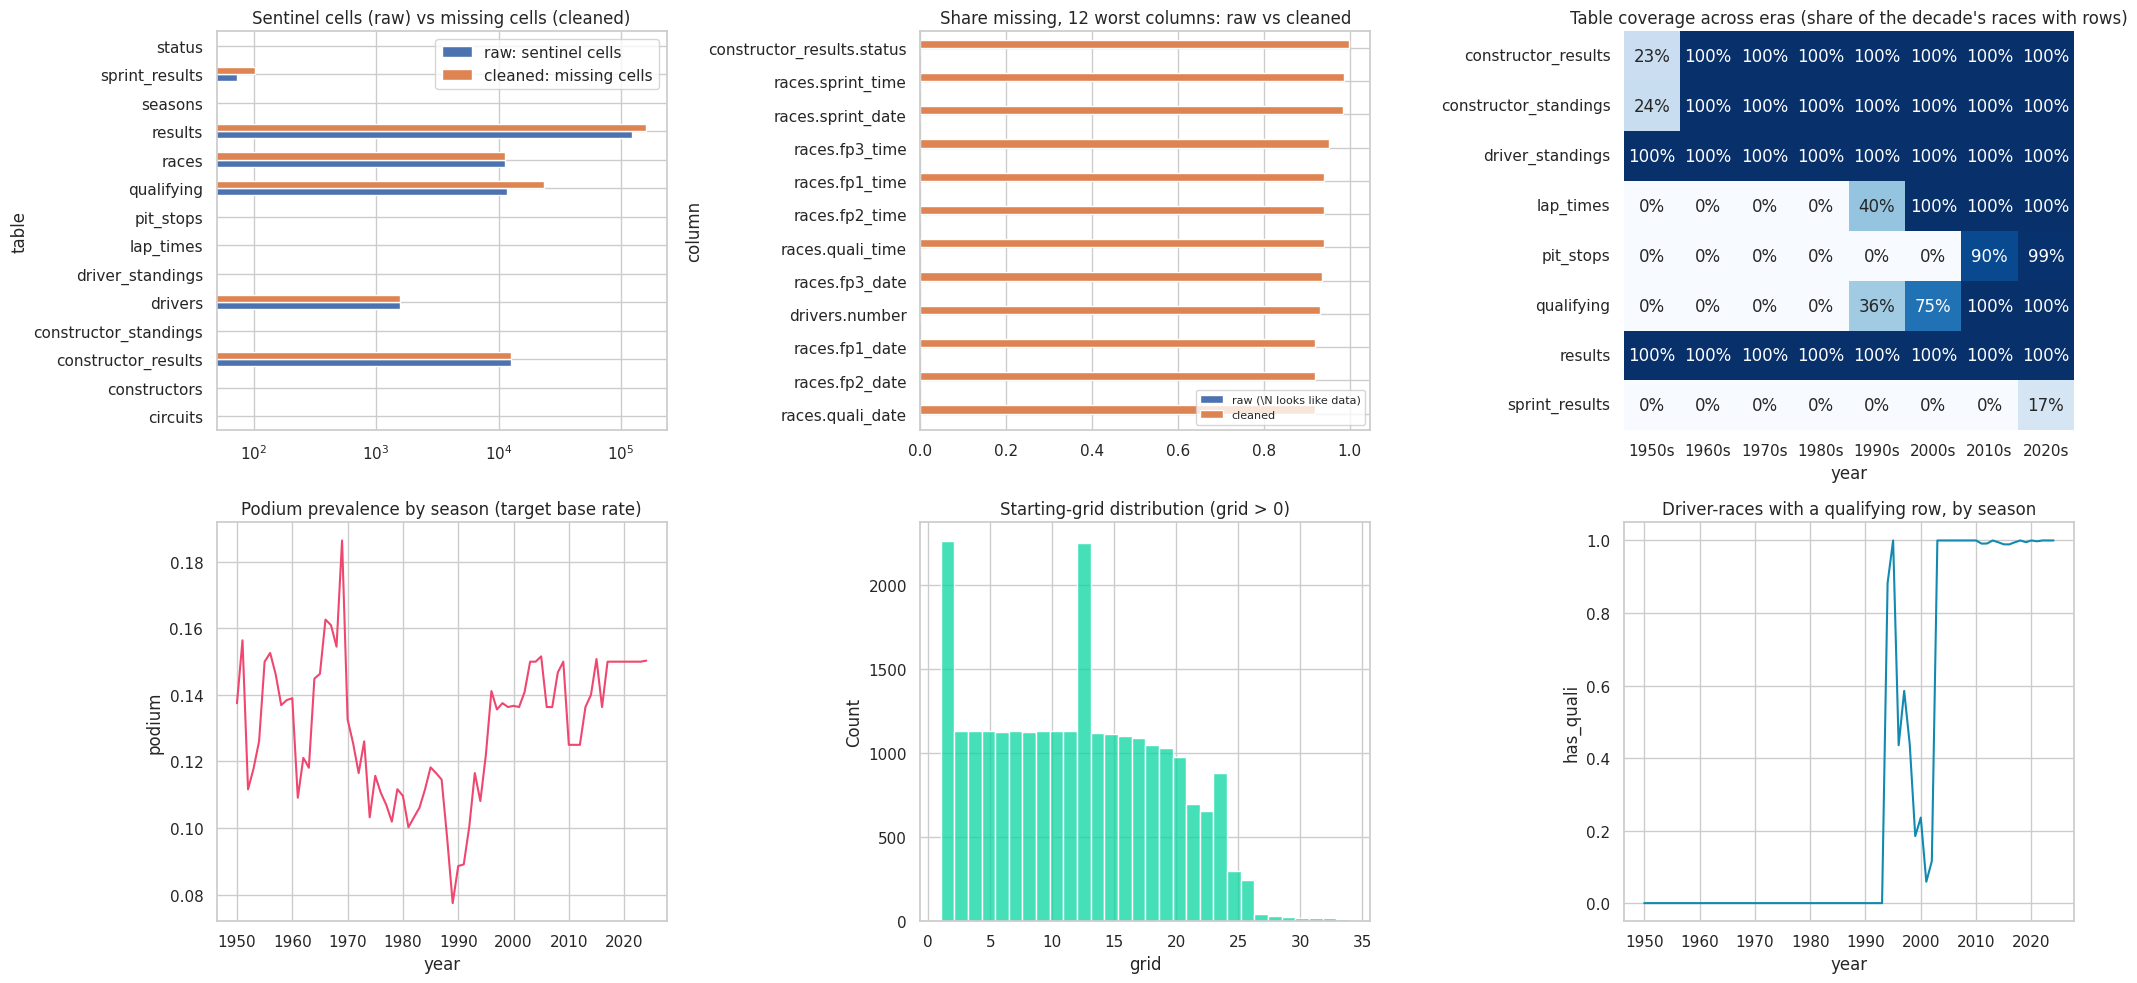

**EDA findings** (supported by the figure above). (1) Cleaning exposes missingness that was hidden by the sentinel: `results.position` is 41% missing after cleaning but 0% blank before, because `\N` looked like data. (2) Table coverage is strongly era-dependent: qualifying rows start in 1994 and cover 39% of all driver-races (85% from 1994 on), so qualifying features need explicit missing flags and imputation. (3) The podium base rate drifts with field size, from 13.6% in the 1950s to 15.0% in the 2020s, so early and modern seasons are not exchangeable and the train/validation/test split must respect chronology.

In [10]:
section("A.4 EDA on raw vs cleaned tables: missingness, key distributions, table coverage across eras")
race_year = tables["races"].set_index("raceId")["year"]
quali_keys = tables["qualifying"][["raceId", "driverId"]].drop_duplicates().assign(has_quali=1)
res_eda = (tables["results"].assign(year=tables["results"]["raceId"].map(race_year))
           .merge(quali_keys, on=["raceId", "driverId"], how="left"))
res_eda["podium"] = res_eda["positionOrder"] <= 3
res_eda["has_quali"] = res_eda["has_quali"].notna()

miss = pd.DataFrame([
    {"column": f"{t}.{c}", "raw (\\N looks like data)": float((raw[t][c] == "").mean()), "cleaned": float(tables[t][c].isna().mean())}
    for t in TABLES for c in raw[t].columns]).nlargest(12, "cleaned").set_index("column").iloc[::-1]

race_decade = race_year // 10 * 10
coverage = pd.DataFrame({t: pd.Series(race_decade.index.isin(tables[t]["raceId"]), index=race_decade.index).groupby(race_decade).mean()
                         for t in TABLES if "raceId" in tables[t].columns and t != "races"})
coverage.index = coverage.index.astype(int).astype(str) + "s"

fig, axes = plt.subplots(2, 3, figsize=(21, 10))
(raw_summary.set_index("table")["sentinel_cells"].rename("raw: sentinel cells").to_frame()
 .join(cleaning_summary.set_index("table")["missing_cells_after"].rename("cleaned: missing cells"))
 .plot.barh(ax=axes[0, 0], logx=True, title="Sentinel cells (raw) vs missing cells (cleaned)"))
miss.plot.barh(ax=axes[0, 1], title="Share missing, 12 worst columns: raw vs cleaned")
axes[0, 1].legend(loc="lower right", fontsize=8)
sns.heatmap(coverage.T, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=axes[0, 2])
axes[0, 2].set_title("Table coverage across eras (share of the decade's races with rows)")
sns.lineplot(data=res_eda.groupby("year", as_index=False)["podium"].mean(), x="year", y="podium", ax=axes[1, 0], color="#ef476f")
axes[1, 0].set_title("Podium prevalence by season (target base rate)")
sns.histplot(res_eda.loc[res_eda["grid"] > 0, "grid"], bins=30, ax=axes[1, 1], color="#06d6a0")
axes[1, 1].set_title("Starting-grid distribution (grid > 0)")
sns.lineplot(data=res_eda.groupby("year", as_index=False)["has_quali"].mean(), x="year", y="has_quali", ax=axes[1, 2], color="#118ab2")
axes[1, 2].set_title("Driver-races with a qualifying row, by season")
show_fig("A_eda_raw_vs_cleaned")

first_quali = int(res_eda.loc[res_eda["has_quali"], "year"].min())
decade_rate = res_eda.groupby(res_eda["year"] // 10 * 10)["podium"].mean()
pos_raw_blank = float((raw["results"]["position"] == "").mean())
record("eda", f"**EDA findings** (supported by the figure above). (1) Cleaning exposes missingness that was hidden by the sentinel: `results.position` is "
       f"{tables['results']['position'].isna().mean():.0%} missing after cleaning but {pos_raw_blank:.0%} blank before, because `\\N` looked like data. "
       f"(2) Table coverage is strongly era-dependent: qualifying rows start in {first_quali} and cover {res_eda['has_quali'].mean():.0%} of all driver-races "
       f"({res_eda.loc[res_eda['year'] >= first_quali, 'has_quali'].mean():.0%} from {first_quali} on), so qualifying features need explicit missing flags and imputation. "
       f"(3) The podium base rate drifts with field size, from {decade_rate.iloc[0]:.1%} in the {int(decade_rate.index[0])}s to {decade_rate.iloc[-1]:.1%} in the "
       f"{int(decade_rate.index[-1])}s, so early and modern seasons are not exchangeable and the train/validation/test split must respect chronology.")

In [11]:
section("A.5 Driver-race grain: shared drives, retention rule, podium label")
results = tables["results"]
dup = results[results.duplicated(["raceId", "driverId"], keep=False)]

# Retention rule: keep the entry with the most laps; ties -> best classified position; ties -> lowest resultId.
results_one = (results.assign(_laps=results["laps"].fillna(-1))
               .sort_values(["raceId", "driverId", "_laps", "positionOrder", "resultId"], ascending=[True, True, False, True, True])
               .drop_duplicates(["raceId", "driverId"], keep="first").drop(columns="_laps").reset_index(drop=True))
results_one["podium"] = (results_one["positionOrder"] <= 3).astype(int)         # podium label: positionOrder <= 3
assert not results_one.duplicated(["raceId", "driverId"]).any(), "(raceId, driverId) is not unique after de-duplication"

dup_groups = dup.groupby(["raceId", "driverId"])
dup_audit = pd.DataFrame([{
    "rows_before": len(results), "duplicate_rows": len(dup), "duplicate_groups": dup_groups.ngroups,
    "rows_removed": len(results) - len(results_one), "rows_after": len(results_one), "duplicate_keys_after": 0,
    "groups_with_conflicting_podium_label": int((dup_groups["positionOrder"].apply(lambda s: s.le(3).nunique()) > 1).sum()),
    "podium_rows_before": int((results["positionOrder"] <= 3).sum()), "podium_rows_after": int(results_one["podium"].sum())}])
results_one.to_csv(OUT_DIR / "driver_race_base.csv", index=False)
dup_audit.to_csv(OUT_DIR / "driver_race_duplicate_audit.csv", index=False)
display(dup.merge(tables["races"][["raceId", "year"]], on="raceId")
        [["year", "raceId", "driverId", "resultId", "constructorId", "laps", "positionOrder", "points"]]
        .sort_values(["year", "raceId", "driverId", "laps"], ascending=[True, True, True, False]).head(8))
display(dup_audit)
record("grain", f"**Grain.** `results` holds {dup_audit.loc[0, 'duplicate_rows']} rows in {dup_audit.loc[0, 'duplicate_groups']} repeated `(raceId, driverId)` groups "
       "(historical shared drives). Rule: keep the entry with the most laps, then the better `positionOrder`, then the lowest `resultId`, so each driver keeps "
       f"the entry that best represents their race. {dup_audit.loc[0, 'rows_removed']} rows were removed, the key is verified unique afterwards "
       f"({dup_audit.loc[0, 'rows_after']:,} rows), and {dup_audit.loc[0, 'groups_with_conflicting_podium_label']} groups had conflicting podium labels "
       f"(podium rows {dup_audit.loc[0, 'podium_rows_before']} before, {dup_audit.loc[0, 'podium_rows_after']} after). "
       "Podium is `positionOrder <= 3`; `laps` is used only to choose between duplicate rows, never as a predictor.")

#### A.5 Driver-race grain: shared drives, retention rule, podium label

,year,raceId,driverId,resultId,constructorId,laps,positionOrder,points
88,1950,835,529,20179,113,136,5,1.0
84,1950,835,529,20097,150,30,31,0.0
89,1950,838,627,20182,154,56,6,0.0
85,1950,838,627,20143,154,10,12,0.0
91,1950,839,579,20184,51,34,13,0.0
86,1950,839,579,20164,51,23,15,1.0
90,1950,839,647,20183,6,80,2,3.0
87,1950,839,647,20166,6,21,17,0.0


,rows_before,duplicate_rows,duplicate_groups,rows_removed,rows_after,duplicate_keys_after,groups_with_conflicting_podium_label,podium_rows_before,podium_rows_after
0,26759,176,85,91,26668,0,21,3397,3395


**Grain.** `results` holds 176 rows in 85 repeated `(raceId, driverId)` groups (historical shared drives). Rule: keep the entry with the most laps, then the better `positionOrder`, then the lowest `resultId`, so each driver keeps the entry that best represents their race. 91 rows were removed, the key is verified unique afterwards (26,668 rows), and 21 groups had conflicting podium labels (podium rows 3397 before, 3395 after). Podium is `positionOrder <= 3`; `laps` is used only to choose between duplicate rows, never as a predictor.

#### A.6 Data-Engineering Q1: front-row-to-podium conversion by circuit, before vs after the 2014 hybrid era

,circuit,starts,podiums,rate
39,Miami International Autodrome,6,6,1.000000
33,Jeddah Corniche Circuit,8,7,0.875000
23,Circuit of the Americas,24,20,0.833333
13,Buddh International Circuit,6,5,0.833333
52,Sochi Autodrom,16,13,0.812500
21,Circuit de Nevers Magny-Cours,36,29,0.805556
56,Yas Marina Circuit,32,25,0.781250
1,Aintree,9,7,0.777778
53,Suzuka Circuit,68,51,0.750000
26,Dijon-Prenois,12,9,0.750000


,front-row definition,era,starts,podiums,rate
0,starting grid,2014+ hybrid,454,345,0.759912
1,starting grid,pre-2014,1789,1002,0.560089
0,qualifying position,2014+ hybrid,456,336,0.736842
1,qualifying position,pre-2014,532,344,0.646617


,driver_race_rows,share_with_qualifying_row
era,,
2014+ hybrid,4626,0.996541
pre-2014,22042,0.266945


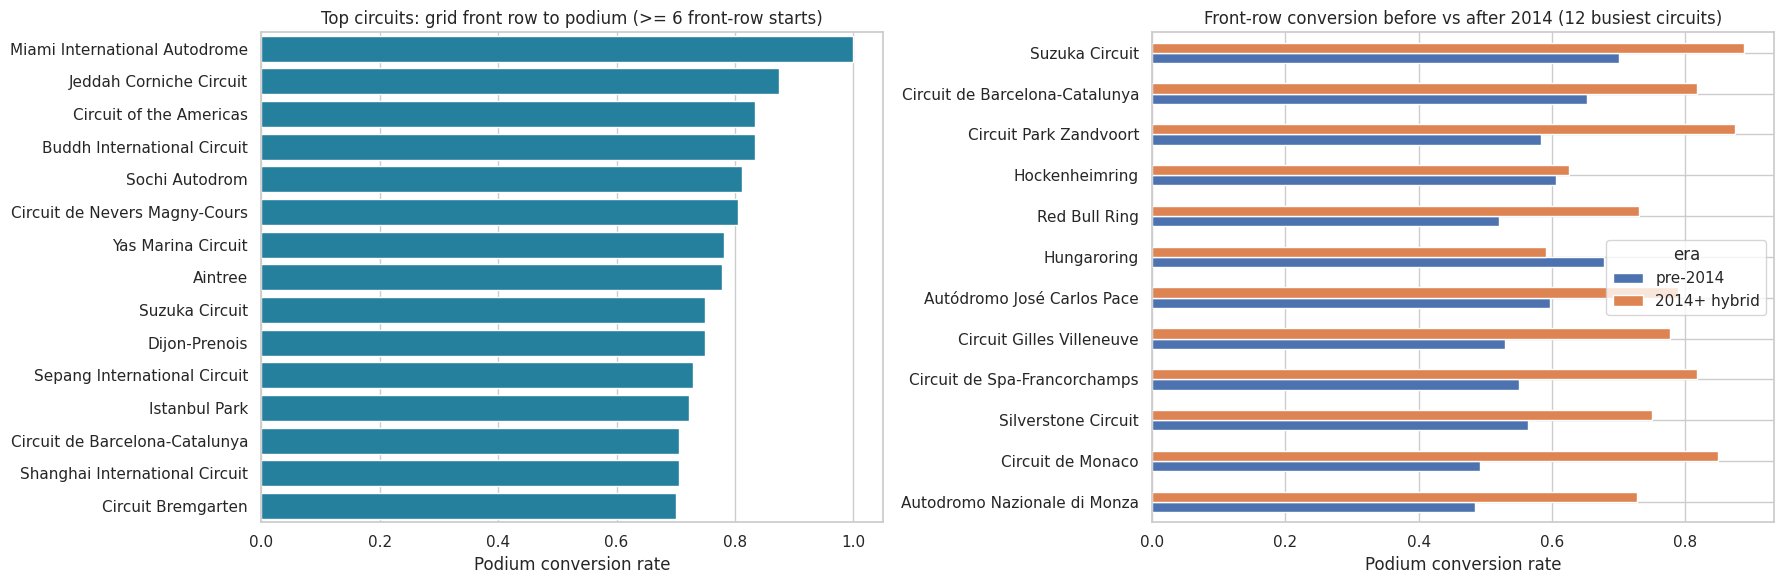

**Q1 answer.** Grain: one row per driver-race from the validated unique base (26,668 rows); a 'front-row start' is grid position 1-2, and the final `positionOrder <= 3` is only the outcome. Highest overall conversion: **Miami International Autodrome** (100.0% over 6 front-row starts). Across the 23 circuits with enough front-row starts in both eras, the circuit ranking before and after 2014 has Spearman rank correlation -0.02; the largest change is Circuit de Monaco (+35.8%). Qualifying position is tracked separately from grid because penalties move the grid; qualifying rows exist for only 27% of pre-2014 and 100% of 2014+ driver-races, so the pre-2014 qualifying-based rate rests on a partial sample.

In [12]:
section("A.6 Data-Engineering Q1: front-row-to-podium conversion by circuit, before vs after the 2014 hybrid era")
q1 = (results_one[["raceId", "driverId", "grid", "positionOrder"]]
      .merge(tables["races"][["raceId", "year", "circuitId"]], on="raceId", how="left")
      .merge(tables["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit"}), on="circuitId", how="left")
      .merge(tables["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_position"}),
             on=["raceId", "driverId"], how="left"))
q1["podium"] = q1["positionOrder"] <= 3                                  # final result is used only as the outcome
q1["era"] = np.where(q1["year"] >= 2014, "2014+ hybrid", "pre-2014")
q1["front_row_grid"] = q1["grid"].between(1, 2)                          # starting grid (penalties applied)
q1["front_row_quali"] = q1["quali_position"].between(1, 2)               # qualifying classification, kept separate from grid

def conversion(flag, by, min_starts):
    out = q1[q1[flag]].groupby(by).agg(starts=("podium", "size"), podiums=("podium", "sum"), rate=("podium", "mean"))
    return out[out["starts"] >= min_starts].reset_index()

by_circuit = conversion("front_row_grid", ["circuit"], 6).sort_values(["rate", "starts"], ascending=False)
by_circuit_era = conversion("front_row_grid", ["circuit", "era"], 4)
era_wide = by_circuit_era.pivot(index="circuit", columns="era", values="rate").dropna()
era_wide["change"] = era_wide["2014+ hybrid"] - era_wide["pre-2014"]
by_definition = pd.concat({"starting grid": conversion("front_row_grid", ["era"], 1),
                           "qualifying position": conversion("front_row_quali", ["era"], 1)}, names=["front-row definition"]).reset_index(level=0)
quali_coverage = q1.groupby("era").agg(driver_race_rows=("podium", "size"), share_with_qualifying_row=("quali_position", lambda s: s.notna().mean()))
display(by_circuit.head(10)); display(by_definition); display(quali_coverage)

volume = by_circuit_era.groupby("circuit")["starts"].sum()
plot_era = era_wide.assign(starts=volume.reindex(era_wide.index)).nlargest(12, "starts")
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.barplot(data=by_circuit.head(15), x="rate", y="circuit", ax=axes[0], color="#118ab2")
axes[0].set(title="Top circuits: grid front row to podium (>= 6 front-row starts)", xlabel="Podium conversion rate", ylabel="")
plot_era[["pre-2014", "2014+ hybrid"]].plot.barh(ax=axes[1], title="Front-row conversion before vs after 2014 (12 busiest circuits)")
axes[1].set(xlabel="Podium conversion rate", ylabel="")
show_fig("A_q1_front_row_conversion")

rank_corr = era_wide["pre-2014"].corr(era_wide["2014+ hybrid"], method="spearman") if len(era_wide) > 2 else np.nan
big = era_wide["change"].abs().idxmax() if len(era_wide) else "n/a"
top = by_circuit.iloc[0]
record("q1", f"**Q1 answer.** Grain: one row per driver-race from the validated unique base ({len(q1):,} rows); a 'front-row start' is grid position 1-2, and the final "
       f"`positionOrder <= 3` is only the outcome. Highest overall conversion: **{top['circuit']}** ({top['rate']:.1%} over {int(top['starts'])} front-row starts). "
       f"Across the {len(era_wide)} circuits with enough front-row starts in both eras, the circuit ranking before and after 2014 has Spearman rank correlation "
       f"{rank_corr:.2f}; the largest change is {big} ({era_wide['change'].loc[big]:+.1%}). Qualifying position is tracked separately from grid because penalties move the grid; "
       f"qualifying rows exist for only {quali_coverage.loc['pre-2014', 'share_with_qualifying_row']:.0%} of pre-2014 and "
       f"{quali_coverage.loc['2014+ hybrid', 'share_with_qualifying_row']:.0%} of 2014+ driver-races, so the pre-2014 qualifying-based rate rests on a partial sample.")

# Part B: Feature plan, leakage-safe modeling table, Data-Engineering Q3 and Q2

Predictors are restricted to the **post-qualifying, pre-race cutoff**. Form and standings use only races *before* the current one. Current-race results, status, points, laps, pit stops and post-race standings are excluded; the podium outcome is kept separate from the predictors.

In [13]:
section("B.1 Feature plan: candidate groups, availability at the cutoff, exclusions")
numeric_features = [
    "year", "round", "grid_position", "grid_zero_or_unknown", "qualifying_position", "q1_sec", "q2_sec", "q3_sec", "best_qualifying_sec",
    "completed_q3", "qualifying_missing", "qualifying_gap_to_pole", "qualifying_position_delta_to_grid", "driverAgeYears", "driver_home_race",
    "lat", "lng", "alt", "driver_prev_points", "driver_prev_position", "driver_prev_wins", "constructor_prev_points",
    "constructor_prev_position", "constructor_prev_wins", "driver_form_podium_rate_5", "driver_form_avg_finish_5", "driver_form_points_5",
    "constructor_form_podium_rate_5", "constructor_form_avg_finish_5", "constructor_form_points_5"]
categorical_features = ["circuitId", "driverNationality", "constructorNationality", "circuitCountryNorm"]
ID_FEATURES = ["driverId", "constructorId"]            # entity IDs: identifiers always, predictors only if DROP_ENTITY_IDS is False
if not DROP_ENTITY_IDS:
    categorical_features = categorical_features + ID_FEATURES
feature_columns = numeric_features + categorical_features

FEATURE_GROUPS = {
    "grid": ["grid_position", "grid_zero_or_unknown"],
    "qualifying": ["qualifying_position", "q1_sec", "q2_sec", "q3_sec", "best_qualifying_sec", "completed_q3", "qualifying_missing",
                   "qualifying_gap_to_pole", "qualifying_position_delta_to_grid"],
    "standings": ["driver_prev_points", "driver_prev_position", "driver_prev_wins", "constructor_prev_points",
                  "constructor_prev_position", "constructor_prev_wins"],
    "form": ["driver_form_podium_rate_5", "driver_form_avg_finish_5", "driver_form_points_5",
             "constructor_form_podium_rate_5", "constructor_form_avg_finish_5", "constructor_form_points_5"],
    "context": ["year", "round", "driverAgeYears", "driver_home_race", "lat", "lng", "alt", "circuitId", "driverNationality",
                "constructorNationality", "circuitCountryNorm"] + ([] if DROP_ENTITY_IDS else ID_FEATURES)}
assert sorted(feature_columns) == sorted(sum(FEATURE_GROUPS.values(), [])), "feature groups and feature lists disagree"

GROUP_AVAILABILITY = {
    "grid": ("post-qualifying, pre-race", "The starting grid, penalties included, is set when qualifying ends and before lights-out."),
    "qualifying": ("post-qualifying, pre-race", "Q1/Q2/Q3 classification and lap times are final when qualifying ends; gap to pole uses qualifying times only."),
    "standings": ("before the current race", "Championship points, position and wins as of the previous round of the same season (shifted one race)."),
    "form": ("before the current race", "Rolling 5-race podium rate, finishing position and points over earlier races only (shift before rolling)."),
    "context": ("pre-race, calendar or entry list", "Season, round, circuit location, driver age on race day, home-race flag and nationalities are known in advance.")}
feature_plan = pd.DataFrame([
    {"group": g, "n_features": len(cols), "available_at": GROUP_AVAILABILITY[g][0], "justification": GROUP_AVAILABILITY[g][1],
     "features": ", ".join(cols)} for g, cols in FEATURE_GROUPS.items()])
display(feature_plan)
record("id_decision", "**Entity-ID decision (Part B feature list; needs team sign-off).** `driverId` and `constructorId` are not predictors: one-hot IDs let a model "
       "memorise past drivers and teams, which does not transfer to new seasons. They stay in the modeling table as row identifiers only. "
       "`DROP_ENTITY_IDS` in the setup cell is the single switch; Part C's ablation includes an 'add driverId + constructorId' row that re-tests this "
       "on validation data, and setting the switch to `False` restores them as predictors everywhere.")
record("exclusions", "**Excluded from predictors:** the current race's `positionOrder` (target only), points, laps, race time, fastest-lap fields, status, "
       "pit stops, lap times and post-race standings.")

#### B.1 Feature plan: candidate groups, availability at the cutoff, exclusions

,group,n_features,available_at,justification,features
0,grid,2,"post-qualifying, pre-race","The starting grid, penalties included, is set ...","grid_position, grid_zero_or_unknown"
1,qualifying,9,"post-qualifying, pre-race",Q1/Q2/Q3 classification and lap times are fina...,"qualifying_position, q1_sec, q2_sec, q3_sec, b..."
2,standings,6,before the current race,"Championship points, position and wins as of t...","driver_prev_points, driver_prev_position, driv..."
3,form,6,before the current race,"Rolling 5-race podium rate, finishing position...","driver_form_podium_rate_5, driver_form_avg_fin..."
4,context,11,"pre-race, calendar or entry list","Season, round, circuit location, driver age on...","year, round, driverAgeYears, driver_home_race,..."


**Entity-ID decision (Part B feature list; needs team sign-off).** `driverId` and `constructorId` are not predictors: one-hot IDs let a model memorise past drivers and teams, which does not transfer to new seasons. They stay in the modeling table as row identifiers only. `DROP_ENTITY_IDS` in the setup cell is the single switch; Part C's ablation includes an 'add driverId + constructorId' row that re-tests this on validation data, and setting the switch to `False` restores them as predictors everywhere.

**Excluded from predictors:** the current race's `positionOrder` (target only), points, laps, race time, fastest-lap fields, status, pit stops, lap times and post-race standings.

In [14]:
section("B.2 Modeling table: one row per (raceId, driverId), pre-race features only")
NATIONALITY_TO_COUNTRY = {
    "American": "USA", "Argentine": "Argentina", "Australian": "Australia", "Austrian": "Austria", "Belgian": "Belgium",
    "Brazilian": "Brazil", "British": "UK", "Canadian": "Canada", "Chilean": "Chile", "Chinese": "China", "Colombian": "Colombia",
    "Czech": "Czech Republic", "Danish": "Denmark", "Dutch": "Netherlands", "Finnish": "Finland", "French": "France", "German": "Germany",
    "Hungarian": "Hungary", "Indian": "India", "Indonesian": "Indonesia", "Irish": "Ireland", "Italian": "Italy", "Japanese": "Japan",
    "Liechtensteiner": "Liechtenstein", "Malaysian": "Malaysia", "Mexican": "Mexico", "Monegasque": "Monaco", "New Zealander": "New Zealand",
    "Polish": "Poland", "Portuguese": "Portugal", "Rhodesian": "Zimbabwe", "Russian": "Russia", "South African": "South Africa",
    "Spanish": "Spain", "Swedish": "Sweden", "Swiss": "Switzerland", "Thai": "Thailand", "Uruguayan": "Uruguay", "Venezuelan": "Venezuela"}
COUNTRY_ALIASES = {"United States": "USA", "United States of America": "USA", "Great Britain": "UK", "United Kingdom": "UK",
                   "United Arab Emirates": "UAE", "South Korea": "Korea"}

races = tables["races"][["raceId", "year", "round", "circuitId", "date"]]
circuits = tables["circuits"][["circuitId", "country", "lat", "lng", "alt"]].assign(
    circuitCountryNorm=lambda d: d["country"].replace(COUNTRY_ALIASES))
drivers = tables["drivers"][["driverId", "dob", "nationality"]].rename(columns={"nationality": "driverNationality"})
constructors = tables["constructors"][["constructorId", "nationality"]].rename(columns={"nationality": "constructorNationality"})
qual = tables["qualifying"][["raceId", "driverId", "position", "q1_sec", "q2_sec", "q3_sec"]].rename(columns={"position": "qualifying_position"})
qual["best_qualifying_sec"] = qual[["q1_sec", "q2_sec", "q3_sec"]].min(axis=1)
qual["completed_q3"] = qual["q3_sec"].notna().astype(int)

df = (results_one[["raceId", "driverId", "constructorId", "grid", "positionOrder"]]
      .merge(races, on="raceId", how="left")
      .merge(circuits[["circuitId", "circuitCountryNorm", "lat", "lng", "alt"]], on="circuitId", how="left")
      .merge(drivers, on="driverId", how="left").merge(constructors, on="constructorId", how="left")
      .merge(qual, on=["raceId", "driverId"], how="left"))
df["podium"] = (df["positionOrder"] <= 3).astype(int)                               # outcome only, never a predictor
df["grid_position"] = df["grid"].where(df["grid"] > 0)
df["grid_zero_or_unknown"] = (df["grid"].fillna(0) <= 0).astype(int)
df["driverAgeYears"] = (df["date"] - df["dob"]).dt.days / 365.25
df["driver_home_race"] = (df["driverNationality"].map(NATIONALITY_TO_COUNTRY) == df["circuitCountryNorm"]).astype(int)
df["qualifying_missing"] = df["qualifying_position"].isna().astype(int)
df["qualifying_gap_to_pole"] = df["best_qualifying_sec"] - df.groupby("raceId")["best_qualifying_sec"].transform("min")
df["qualifying_position_delta_to_grid"] = df["grid_position"] - df["qualifying_position"]

def prior_standings(standings, entity, prefix):
    """Standings after the previous round of the same season (shift(1) within season and entity)."""
    st = standings.merge(tables["races"][["raceId", "year", "round"]], on="raceId").sort_values(["year", "round"])
    cols = ["points", "position", "wins"]
    for c in cols:
        st[f"{prefix}_prev_{c}"] = st.groupby(["year", entity])[c].shift(1)
    return st[["raceId", entity] + [f"{prefix}_prev_{c}" for c in cols]]

df = df.merge(prior_standings(tables["driver_standings"], "driverId", "driver"), on=["raceId", "driverId"], how="left")
df = df.merge(prior_standings(tables["constructor_standings"], "constructorId", "constructor"), on=["raceId", "constructorId"], how="left")

def prior_mean(series):
    """Mean of the previous 5 observations, excluding the current one."""
    return series.shift(1).rolling(5, min_periods=1).mean()

hist = (results_one[["raceId", "driverId", "constructorId", "positionOrder", "points"]]
        .merge(races[["raceId", "date"]], on="raceId").sort_values(["date", "raceId"]))
hist["podium_hist"] = (hist["positionOrder"] <= 3).astype(int)
for src, name in [("podium_hist", "podium_rate"), ("positionOrder", "avg_finish"), ("points", "points")]:
    hist[f"driver_form_{name}_5"] = hist.groupby("driverId")[src].transform(prior_mean)
con_hist = (hist.groupby(["constructorId", "raceId", "date"], as_index=False)
            .agg(c_podium=("podium_hist", "mean"), c_finish=("positionOrder", "mean"), c_points=("points", "sum"))
            .sort_values(["date", "raceId"]))
for src, name in [("c_podium", "podium_rate"), ("c_finish", "avg_finish"), ("c_points", "points")]:
    con_hist[f"constructor_form_{name}_5"] = con_hist.groupby("constructorId")[src].transform(prior_mean)
df = df.merge(hist[["raceId", "driverId"] + [c for c in hist.columns if c.startswith("driver_form_")]], on=["raceId", "driverId"], how="left")
df = df.merge(con_hist[["raceId", "constructorId"] + [c for c in con_hist.columns if c.startswith("constructor_form_")]],
              on=["raceId", "constructorId"], how="left")

for col in categorical_features:                                   # categorical predictors as strings (NaN kept)
    df[col] = df[col].astype(object).where(df[col].isna(), df[col].astype(str))

LEAKY_FIELDS = {"positionOrder", "position", "points", "laps", "milliseconds", "race_time_sec", "fastestLap", "fastestLapTime",
                "fastestLapSpeed", "rank", "statusId", "status"}
ID_COLUMNS = ["raceId", "driverId", "constructorId"]
modeling_data = df[list(dict.fromkeys(ID_COLUMNS + feature_columns + ["podium"]))].copy()

checks = []
def add_check(name, value, passed, note):
    checks.append({"check": name, "value": value, "passes": bool(passed), "note": note})
add_check("one row per (raceId, driverId)", f"{len(modeling_data):,} rows",
          not modeling_data.duplicated(["raceId", "driverId"]).any() and len(modeling_data) == len(results_one), "no rows lost or duplicated by the joins")
add_check("identifiers non-null", int(modeling_data[ID_COLUMNS].isna().sum().sum()), modeling_data[ID_COLUMNS].notna().all().all(), "raceId, driverId, constructorId present")
add_check("no post-race field is a predictor", sorted(LEAKY_FIELDS & (set(feature_columns) | set(modeling_data.columns))) or "none",
          not LEAKY_FIELDS & (set(feature_columns) | set(modeling_data.columns)), "results fields used for the target or for prior-race form never reach the table")
add_check("target separate from predictors", sorted(modeling_data["podium"].unique().tolist()), "podium" not in feature_columns and set(modeling_data["podium"]) <= {0, 1}, "podium is the outcome column only")
add_check("no predictor is entirely missing", int((modeling_data[feature_columns].isna().mean() >= 1).sum()), (modeling_data[feature_columns].isna().mean() < 1).all(), "missingness is allowed and profiled in the data dictionary")
first_driver = hist.groupby("driverId").head(1)
first_constructor = con_hist.groupby("constructorId").head(1)
add_check("driver form excludes the current race", bool(first_driver["driver_form_podium_rate_5"].isna().all()), first_driver["driver_form_podium_rate_5"].isna().all(), "a driver's first race has no prior form")
add_check("constructor form excludes the current race", bool(first_constructor["constructor_form_podium_rate_5"].isna().all()), first_constructor["constructor_form_podium_rate_5"].isna().all(), "a constructor's first race has no prior form")
round_one = modeling_data.loc[modeling_data["round"] == 1, ["driver_prev_points", "constructor_prev_points"]]
add_check("standings are from earlier rounds only", bool(round_one.isna().all().all()), round_one.isna().all().all(), "round-1 rows have no previous same-season standings")
validation_checks = pd.DataFrame(checks)
assert validation_checks["passes"].all(), validation_checks[~validation_checks["passes"]]
modeling_data.to_csv(OUT_DIR / "modeling_table.csv", index=False)
validation_checks.to_csv(OUT_DIR / "modeling_validation_checks.csv", index=False)
display(validation_checks)
display(modeling_data[feature_columns].isna().mean().sort_values(ascending=False).head(10).rename("missing share").to_frame().T)

#### B.2 Modeling table: one row per (raceId, driverId), pre-race features only

,check,value,passes,note
0,"one row per (raceId, driverId)","26,668 rows",True,no rows lost or duplicated by the joins
1,identifiers non-null,0,True,"raceId, driverId, constructorId present"
2,no post-race field is a predictor,none,True,results fields used for the target or for prio...
3,target separate from predictors,"[0, 1]",True,podium is the outcome column only
4,no predictor is entirely missing,0,True,missingness is allowed and profiled in the dat...
5,driver form excludes the current race,True,True,a driver's first race has no prior form
6,constructor form excludes the current race,True,True,a constructor's first race has no prior form
7,standings are from earlier rounds only,True,True,round-1 rows have no previous same-season stan...


,q3_sec,q2_sec,qualifying_gap_to_pole,best_qualifying_sec,q1_sec,qualifying_position_delta_to_grid,qualifying_position,completed_q3,driver_prev_position,driver_prev_wins
missing share,0.863919,0.780748,0.612344,0.612344,0.612344,0.609757,0.606495,0.606495,0.137281,0.137281


#### B.3 Evidence for the feature plan (training seasons only) and the feature / data dictionary

,feature,group,type,available_at,missing_share,spearman_with_podium_train
0,year,context,numeric,"pre-race, calendar or entry list",0.000,0.012
1,round,context,numeric,"pre-race, calendar or entry list",0.000,-0.004
2,grid_position,grid,numeric,"post-qualifying, pre-race",0.061,-0.449
3,grid_zero_or_unknown,grid,numeric,"post-qualifying, pre-race",0.000,-0.100
4,qualifying_position,qualifying,numeric,"post-qualifying, pre-race",0.606,-0.484
5,q1_sec,qualifying,numeric,"post-qualifying, pre-race",0.612,-0.045
6,q2_sec,qualifying,numeric,"post-qualifying, pre-race",0.781,-0.034
7,q3_sec,qualifying,numeric,"post-qualifying, pre-race",0.864,-0.035
8,best_qualifying_sec,qualifying,numeric,"post-qualifying, pre-race",0.612,-0.060
9,completed_q3,qualifying,numeric,"post-qualifying, pre-race",0.606,0.298


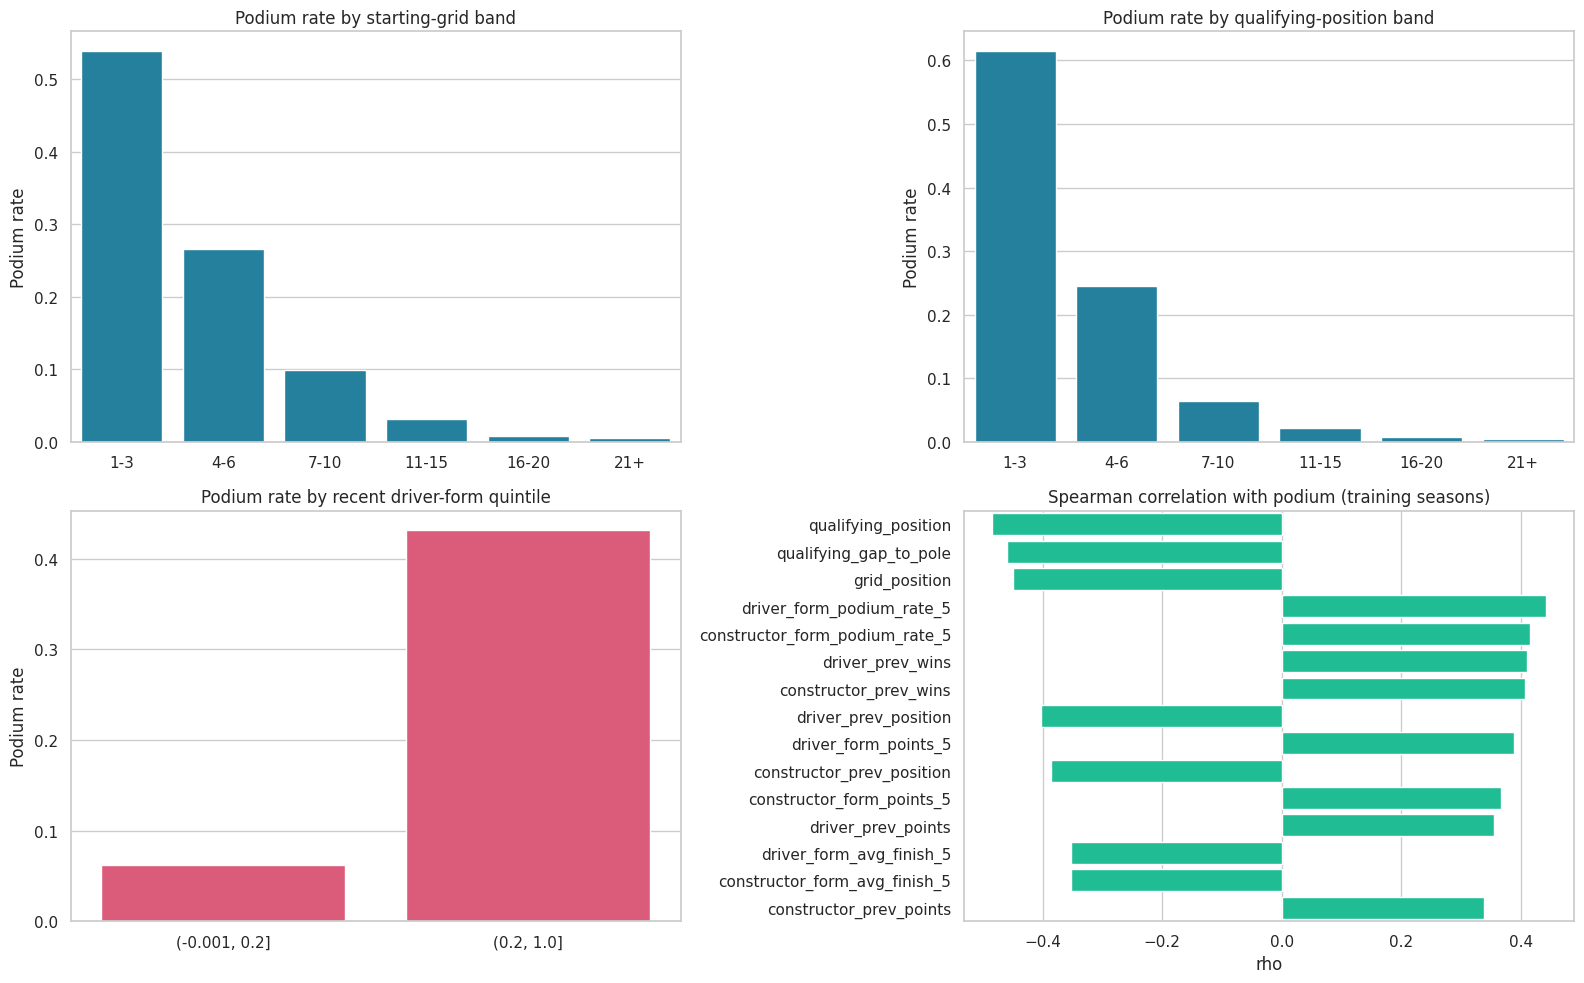

**Feature-plan evidence** (training seasons <= 2018 only). Podium rate falls steeply with starting-grid and qualifying band, and rises with recent driver form (figure above); the strongest rank correlations with the podium are `qualifying_position`, `qualifying_gap_to_pole`, `grid_position`, `driver_form_podium_rate_5` (|rho| 0.48 for the first, 0.44 for the fourth). Grid and qualifying overlap heavily (grid is mostly qualifying order plus penalties) and so do form and standings, which Part C's group ablation quantifies. Every predictor group is available by the post-qualifying, pre-race cutoff (table in B.1).

In [15]:
section("B.3 Evidence for the feature plan (training seasons only) and the feature / data dictionary")
BANDS, BAND_LABELS = [0, 3, 6, 10, 15, 20, 99], ["1-3", "4-6", "7-10", "11-15", "16-20", "21+"]
train_rows = modeling_data[modeling_data["year"] <= TRAIN_END]       # evidence never looks at validation/test seasons
rho = train_rows[numeric_features + ["podium"]].corr(method="spearman")["podium"].drop("podium")

group_of = {f: g for g, cols in FEATURE_GROUPS.items() for f in cols}
feature_dictionary = pd.DataFrame({
    "feature": feature_columns, "group": [group_of[f] for f in feature_columns],
    "type": ["numeric" if f in numeric_features else "categorical" for f in feature_columns],
    "available_at": [GROUP_AVAILABILITY[group_of[f]][0] for f in feature_columns],
    "missing_share": [modeling_data[f].isna().mean() for f in feature_columns],
    "spearman_with_podium_train": [rho.get(f, np.nan) for f in feature_columns]})
feature_dictionary.to_csv(OUT_DIR / "feature_data_dictionary.csv", index=False)
display(feature_dictionary.round(3))

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, col, title in [(axes[0, 0], "grid_position", "Podium rate by starting-grid band"),
                       (axes[0, 1], "qualifying_position", "Podium rate by qualifying-position band")]:
    rate = train_rows.groupby(pd.cut(train_rows[col], BANDS, labels=BAND_LABELS, include_lowest=True), observed=True)["podium"].mean()
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#118ab2")
    ax.set(title=title, ylabel="Podium rate", xlabel="")
form = train_rows.dropna(subset=["driver_form_podium_rate_5"])
form_rate = form.groupby(pd.qcut(form["driver_form_podium_rate_5"], 5, duplicates="drop"), observed=True)["podium"].mean()
sns.barplot(x=form_rate.index.astype(str), y=form_rate.values, ax=axes[1, 0], color="#ef476f")
axes[1, 0].set(title="Podium rate by recent driver-form quintile", ylabel="Podium rate", xlabel="")
top_rho = rho.reindex(rho.abs().sort_values(ascending=False).index).head(15)
sns.barplot(x=top_rho.values, y=top_rho.index, ax=axes[1, 1], color="#06d6a0")
axes[1, 1].set(title="Spearman correlation with podium (training seasons)", xlabel="rho", ylabel="")
show_fig("B_feature_evidence")
record("feature_plan", f"**Feature-plan evidence** (training seasons <= {TRAIN_END} only). Podium rate falls steeply with starting-grid and qualifying band, and rises with "
       f"recent driver form (figure above); the strongest rank correlations with the podium are `{'`, `'.join(top_rho.index[:4])}` "
       f"(|rho| {abs(top_rho.iloc[0]):.2f} for the first, {abs(top_rho.iloc[3]):.2f} for the fourth). Grid and qualifying overlap heavily (grid is mostly qualifying order plus penalties) and so do form and "
       "standings, which Part C's group ablation quantifies. Every predictor group is available by the post-qualifying, pre-race cutoff (table in B.1).")

#### B.4 Data-Engineering Q3: mechanical-retirement rate by constructor, 2014-2021 vs 2022-2024

category,finished or lapped,mechanical,crash / driver / regulation,other retirement,did not start
rows,3825,375,319,93,14


,category,status,rows
1,crash / driver / regulation,Collision,150
0,crash / driver / regulation,Accident,85
2,crash / driver / regulation,Collision damage,59
4,crash / driver / regulation,Disqualified,11
6,crash / driver / regulation,Spun off,11
...,...,...,...
65,other retirement,Vibrations,2
51,other retirement,Cooling system,1
52,other retirement,Debris,1
53,other retirement,Drivetrain,1


,period,constructor,starts,mechanical,rate
4,2014-2021,Caterham,34,8,0.235294
8,2014-2021,Lotus F1,75,12,0.160000
17,2014-2021,Toro Rosso,242,37,0.152893
15,2014-2021,Renault,200,29,0.145000
11,2014-2021,McLaren,318,45,0.141509
16,2014-2021,Sauber,200,21,0.105000
1,2014-2021,AlphaTauri,78,8,0.102564
14,2014-2021,Red Bull,319,31,0.097179
21,2022-2024,Alpine F1 Team,136,14,0.102941
19,2022-2024,Alfa Romeo,88,9,0.102273


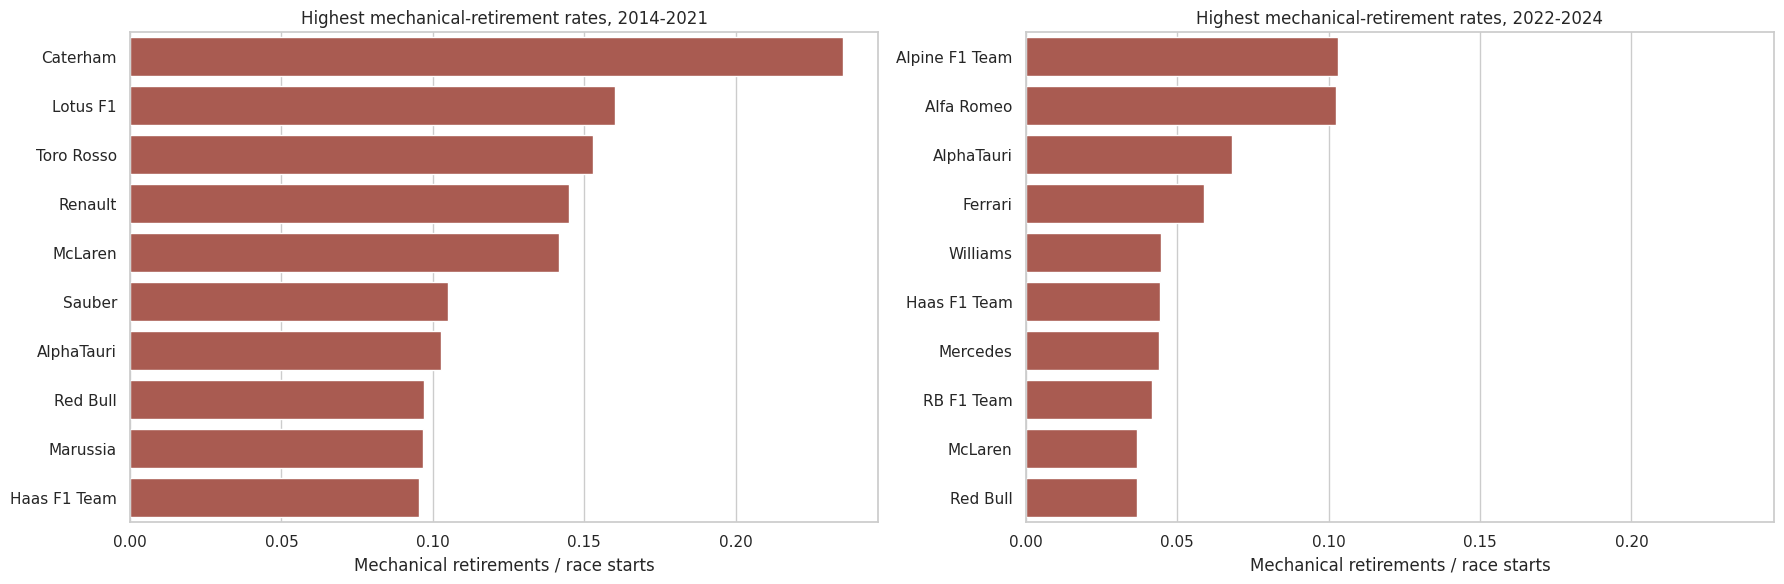

**Q3 answer.** A mechanical retirement is a started race that ended early with a car-component status (engine, gearbox, hydraulics, ...), excluding crash, driver and regulation statuses (status-to-category table above). Denominator = race starts (all results rows except did-not-start statuses). Highest rates: 2014-2021: **Caterham** (23.5%, 8/34 starts); 2022-2024: **Alpine F1 Team** (10.3%, 14/136 starts). Constructors need >= 10 starts. Classification is keyword-based; 2.0% of starts fall in 'other retirement' (generic or ambiguous statuses such as 'Retired'), and 0 results rows have no status. Retirements with ambiguous labels are not counted as mechanical, so the rates are more likely under- than over-stated.

In [16]:
section("B.4 Data-Engineering Q3: mechanical-retirement rate by constructor, 2014-2021 vs 2022-2024")
MECHANICAL = ["engine", "gearbox", "transmission", "clutch", "hydraulic", "electrical", "fuel", "oil", "brake", "suspension", "power", "alternator",
              "battery", "turbo", "ers", "mgu", "water", "radiator", "overheating", "pneumatic", "driveshaft", "wheel", "throttle", "steering",
              "exhaust", "ignition", "spark", "differential", "cv joint", "pump", "pressure", "distributor"]
NON_START = ["did not start", "did not qualify", "not prequalified", "withdrew", "withdrawn"]
CRASH_OR_REGULATION = ["accident", "collision", "spun", "disqualified", "excluded", "damage", "driver"]

q3 = (results_one[["raceId", "driverId", "constructorId", "statusId"]]
      .merge(tables["races"][["raceId", "year"]], on="raceId", how="left")
      .merge(tables["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId", how="left")
      .merge(tables["status"], on="statusId", how="left"))
status_text = q3["status"].fillna("")
def has_any(words):
    return status_text.str.lower().str.contains("|".join(map(re.escape, words)))

# Status -> category mapping. Order matters: non-starts first, then crash/driver/regulation, then mechanical.
q3["category"] = np.select(
    [has_any(NON_START), has_any(CRASH_OR_REGULATION), has_any(MECHANICAL), status_text.eq("Finished") | status_text.str.startswith("+")],
    ["did not start", "crash / driver / regulation", "mechanical", "finished or lapped"], default="other retirement")
# pandas >= 3 refuses to assign strings into a float column, so build the period column in one step instead of np.nan + .loc
q3["period"] = np.select([q3["year"].between(2014, 2021), q3["year"].between(2022, 2024)], ["2014-2021", "2022-2024"], default="")

in_period = q3[q3["period"] != ""]
starts = in_period[in_period["category"] != "did not start"]               # denominator: cars that started the race
q3_rates = (starts.groupby(["period", "constructor"])
            .agg(starts=("category", "size"), mechanical=("category", lambda s: (s == "mechanical").sum())).reset_index())
q3_rates["rate"] = q3_rates["mechanical"] / q3_rates["starts"]
q3_rates = q3_rates[q3_rates["starts"] >= 10].sort_values(["period", "rate", "starts"], ascending=[True, False, False])

status_map = (in_period.groupby(["category", "status"], dropna=False).size().rename("rows").reset_index()
              .sort_values(["category", "rows"], ascending=[True, False]))
display(in_period["category"].value_counts().rename("rows").to_frame().T)
display(status_map)
display(q3_rates.groupby("period").head(8))

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharex=True)
for ax, (period, part) in zip(axes, q3_rates.groupby("period")):
    sns.barplot(data=part.head(10), x="rate", y="constructor", ax=ax, color="#b85042")
    ax.set(title=f"Highest mechanical-retirement rates, {period}", xlabel="Mechanical retirements / race starts", ylabel="")
show_fig("B_q3_mechanical_retirements")

tops = q3_rates.groupby("period").head(1)
other_share = (starts["category"] == "other retirement").mean()
record("q3", "**Q3 answer.** A mechanical retirement is a started race that ended early with a car-component status (engine, gearbox, hydraulics, ...), excluding "
       "crash, driver and regulation statuses (status-to-category table above). Denominator = race starts (all results rows except did-not-start statuses). Highest rates: "
       + "; ".join(f"{r.period}: **{r.constructor}** ({r.rate:.1%}, {int(r.mechanical)}/{int(r.starts)} starts)" for r in tops.itertuples())
       + f". Constructors need >= 10 starts. Classification is keyword-based; {other_share:.1%} of starts fall in 'other retirement' (generic or ambiguous statuses such as "
       f"'Retired'), and {int(status_text.eq('').sum())} results rows have no status. Retirements with ambiguous labels are not counted as mechanical, so the rates are more likely under- than over-stated.")

#### B.5 Data-Engineering Q2: home-country podium rate, controlling for starting position

,missing item,rows,share
0,driver country (nationality not mapped),18,0.000675
1,circuit country,0,0.000000
2,positive starting grid,1635,0.061309


,grid_band,home,starts,podiums,rate
0,1-3,False,3106,1725,0.555377
1,1-3,True,264,145,0.549242
2,11-15,False,5132,154,0.030008
3,11-15,True,469,16,0.034115
4,16-20,False,4732,41,0.008664
5,16-20,True,498,3,0.006024
6,21+,False,2500,12,0.004800
7,21+,True,438,4,0.009132
8,4-6,False,3108,812,0.261261
9,4-6,True,261,64,0.245211


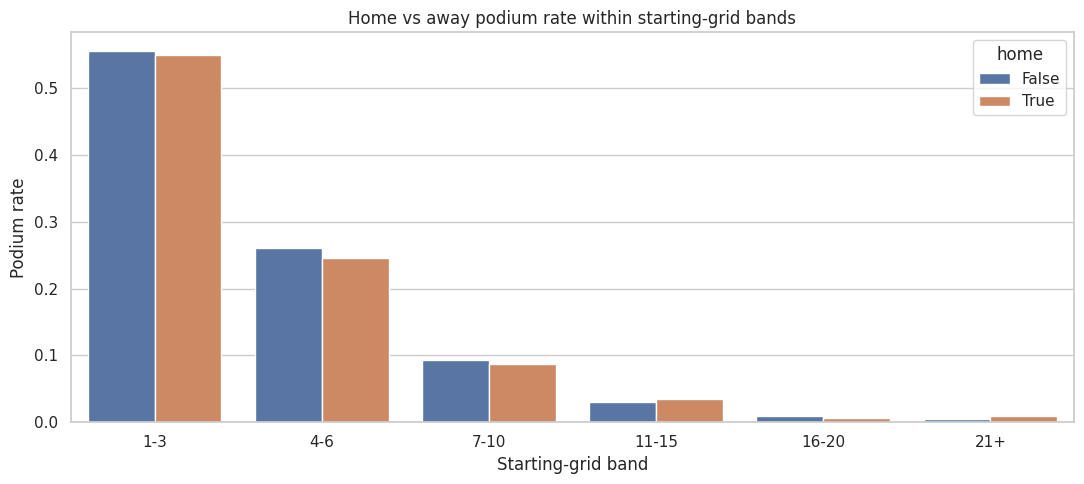

**Q2 answer.** Grain: one row per driver-race (unique base); outcome = final `positionOrder <= 3`. Control: home vs away starts are compared inside six starting-grid bands, then both groups are standardised to the same overall grid-band mix, with a grid-band fixed-effect logistic regression as a check. Grid-standardised podium rate: **0.133 at home vs 0.136 away** (-0.003); home-race odds ratio 0.96 (based on 2,317 home starts of 25,017). Missing data (table above) is dropped, not imputed: 18 rows lack a mapped driver country. Limitations: home country is inferred from driver nationality (manual mapping, no multi-country or changed-nationality cases), home starts are rare, and the result is associational, not causal.

In [17]:
section("B.5 Data-Engineering Q2: home-country podium rate, controlling for starting position")
q2 = (results_one[["raceId", "driverId", "grid", "positionOrder"]]
      .merge(tables["races"][["raceId", "circuitId"]], on="raceId", how="left")
      .merge(circuits[["circuitId", "circuitCountryNorm"]], on="circuitId", how="left")
      .merge(tables["drivers"][["driverId", "nationality"]], on="driverId", how="left"))
q2["driver_country"] = q2["nationality"].map(NATIONALITY_TO_COUNTRY)
q2["grid_pos"] = q2["grid"].where(q2["grid"] > 0)
q2["podium"] = q2["positionOrder"] <= 3                                   # final result is used only as the outcome
missing_country = pd.DataFrame([
    {"missing item": "driver country (nationality not mapped)", "rows": int(q2["driver_country"].isna().sum()), "share": q2["driver_country"].isna().mean()},
    {"missing item": "circuit country", "rows": int(q2["circuitCountryNorm"].isna().sum()), "share": q2["circuitCountryNorm"].isna().mean()},
    {"missing item": "positive starting grid", "rows": int(q2["grid_pos"].isna().sum()), "share": q2["grid_pos"].isna().mean()}])
display(missing_country)

q2 = q2.dropna(subset=["driver_country", "circuitCountryNorm", "grid_pos"]).copy()
q2["home"] = q2["driver_country"] == q2["circuitCountryNorm"]
q2["grid_band"] = pd.cut(q2["grid_pos"], BANDS, labels=BAND_LABELS, include_lowest=True).astype(str)
by_band = q2.groupby(["grid_band", "home"]).agg(starts=("podium", "size"), podiums=("podium", "sum"), rate=("podium", "mean")).reset_index()

# Control: compare home and away starts inside the same grid band, then standardise both groups to the same grid-band mix
rates = by_band.pivot(index="grid_band", columns="home", values="rate").dropna()
weights = q2[q2["grid_band"].isin(rates.index)]["grid_band"].value_counts(normalize=True)
standardised = rates.mul(weights.reindex(rates.index), axis=0).sum()
home_rate, away_rate = standardised.get(True, np.nan), standardised.get(False, np.nan)
common = q2[q2["grid_band"].isin(rates.index)]
design = pd.get_dummies(common[["home", "grid_band"]], columns=["grid_band"], drop_first=True).astype(float)
odds_ratio = float(np.exp(LogisticRegression(max_iter=1000).fit(design, common["podium"]).coef_[0][list(design.columns).index("home")]))
display(by_band)

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=by_band, x="grid_band", y="rate", hue="home", order=[b for b in BAND_LABELS if b in set(by_band["grid_band"])], ax=ax)
ax.set(title="Home vs away podium rate within starting-grid bands", xlabel="Starting-grid band", ylabel="Podium rate")
show_fig("B_q2_home_race")

n_home = int(common["home"].sum())
record("q2", f"**Q2 answer.** Grain: one row per driver-race (unique base); outcome = final `positionOrder <= 3`. Control: home vs away starts are compared inside six "
       f"starting-grid bands, then both groups are standardised to the same overall grid-band mix, with a grid-band fixed-effect logistic regression as a check. "
       f"Grid-standardised podium rate: **{home_rate:.3f} at home vs {away_rate:.3f} away** ({home_rate - away_rate:+.3f}); home-race odds ratio {odds_ratio:.2f} "
       f"(based on {n_home:,} home starts of {len(common):,}). Missing data (table above) is dropped, not imputed: {missing_country.loc[0, 'rows']:,} rows lack a mapped driver country. "
       "Limitations: home country is inferred from driver nationality (manual mapping, no multi-country or changed-nationality cases), home starts are rare, "
       "and the result is associational, not causal.")

# Part C: Chronological split, leakage-safe preprocessing, order experiments, statistical models, evaluation, ablation, permutation importance

Every model sees **identical rows and features**. All preprocessing statistics are learned on training rows only. Hyperparameters, thresholds and preprocessing choices are selected on **validation only**; the test seasons are scored once per final model and never used to choose anything.

#### C.1 Chronological split: train <= 2018, validation 2019-2021, test 2022+

,split,rows,races,first_year,last_year,podium_rate,qualifying_missing_share,grid_missing_share
0,train,24109,997,1950,2018,0.124891,0.670745,0.064955
1,validation,1200,60,2019,2021,0.150000,0.002500,0.024167
2,test,1359,68,2022,2024,0.150110,0.000000,0.029433


,check,passes
0,every row is in exactly one split,True
1,no race appears in two splits,True
2,"train ends before validation, validation befor...",True
3,same feature columns in every split,True
4,target is not a predictor,True
5,both classes present in every split,True


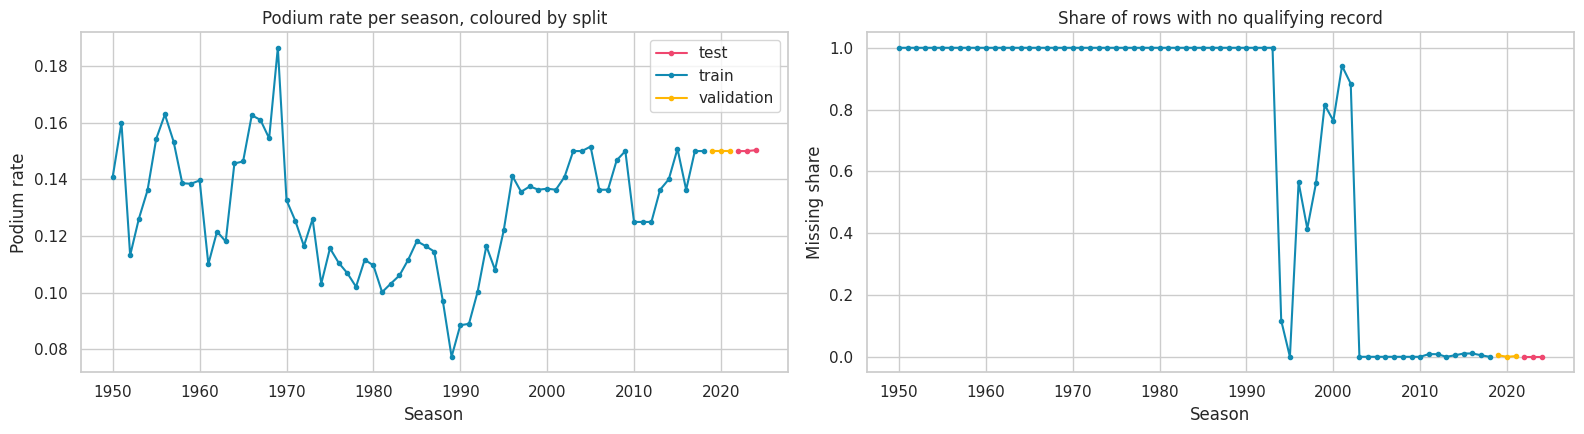

**Split.** Whole seasons, in time order: train 1950-2018 (24,109 rows), validation 2019-2021 (1,200), test 2022-2024 (1,359). A random row split would train on other cars from the same race and on later seasons; splitting by season makes validation and test genuine future predictions and keeps every race, with its three podium places, inside one split. Test covers the 2022+ ground-effect rules, so it also measures transfer to a regulation change. Coverage drift: qualifying is missing for 67% of training rows vs 0% of validation and 0% of test; podium rate is 12.5% / 15.0% / 15.0% because fields shrank. All boundary checks above pass.

In [18]:
section("C.1 Chronological split: train <= 2018, validation 2019-2021, test 2022+")
assert modeling_data["year"].max() > VAL_END, "The dataset must include seasons after the validation window (the test window is 2022+)."
split = pd.Series(np.select([modeling_data["year"] <= TRAIN_END, modeling_data["year"] <= VAL_END], ["train", "validation"], "test"),
                  index=modeling_data.index)
X, y = modeling_data[feature_columns], modeling_data["podium"].astype(int)
X_train, y_train = X[split == "train"], y[split == "train"]
X_val, y_val = X[split == "validation"], y[split == "validation"]
X_test, y_test = X[split == "test"], y[split == "test"]
SPLITS = {"train": (X_train, y_train), "validation": (X_val, y_val), "test": (X_test, y_test)}

years = {s: set(modeling_data.loc[xs.index, "year"]) for s, (xs, _) in SPLITS.items()}
race_sets = {s: set(modeling_data.loc[xs.index, "raceId"]) for s, (xs, _) in SPLITS.items()}
split_checks = pd.DataFrame([
    ("every row is in exactly one split", sum(len(xs) for xs, _ in SPLITS.values()) == len(modeling_data)),
    ("no race appears in two splits", not any(race_sets[a] & race_sets[b] for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")])),
    ("train ends before validation, validation before test", max(years["train"]) < min(years["validation"]) and max(years["validation"]) < min(years["test"])),
    ("same feature columns in every split", all(list(xs.columns) == feature_columns for xs, _ in SPLITS.values())),
    ("target is not a predictor", "podium" not in X.columns),
    ("both classes present in every split", all(ys.nunique() == 2 for _, ys in SPLITS.values()))], columns=["check", "passes"])
assert split_checks["passes"].all(), split_checks
split_summary = pd.DataFrame([
    {"split": s, "rows": len(xs), "races": modeling_data.loc[xs.index, "raceId"].nunique(), "first_year": min(years[s]), "last_year": max(years[s]),
     "podium_rate": ys.mean(), "qualifying_missing_share": modeling_data.loc[xs.index, "qualifying_missing"].mean(),
     "grid_missing_share": xs["grid_position"].isna().mean()} for s, (xs, ys) in SPLITS.items()])
display(split_summary); display(split_checks)

per_season = modeling_data.assign(split=split).groupby(["year", "split"], as_index=False).agg(
    podium_rate=("podium", "mean"), qualifying_missing=("qualifying_missing", "mean"))
palette = {"train": "#118ab2", "validation": "#ffb703", "test": "#ef476f"}
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for name, part in per_season.groupby("split"):
    axes[0].plot(part["year"], part["podium_rate"], marker=".", color=palette[name], label=name)
    axes[1].plot(part["year"], part["qualifying_missing"], marker=".", color=palette[name], label=name)
axes[0].set(title="Podium rate per season, coloured by split", xlabel="Season", ylabel="Podium rate")
axes[1].set(title="Share of rows with no qualifying record", xlabel="Season", ylabel="Missing share")
axes[0].legend()
show_fig("C_split_and_coverage_drift")
s = split_summary.set_index("split")
record("split", f"**Split.** Whole seasons, in time order: train {s.loc['train', 'first_year']}-{s.loc['train', 'last_year']} ({s.loc['train', 'rows']:,} rows), validation "
       f"{s.loc['validation', 'first_year']}-{s.loc['validation', 'last_year']} ({s.loc['validation', 'rows']:,}), test {s.loc['test', 'first_year']}-{s.loc['test', 'last_year']} "
       f"({s.loc['test', 'rows']:,}). A random row split would train on other cars from the same race and on later seasons; splitting by season makes validation and test genuine "
       "future predictions and keeps every race, with its three podium places, inside one split. Test covers the 2022+ ground-effect rules, so it also measures transfer to a regulation change. "
       f"Coverage drift: qualifying is missing for {s.loc['train', 'qualifying_missing_share']:.0%} of training rows vs {s.loc['validation', 'qualifying_missing_share']:.0%} of validation and "
       f"{s.loc['test', 'qualifying_missing_share']:.0%} of test; podium rate is {s.loc['train', 'podium_rate']:.1%} / {s.loc['validation', 'podium_rate']:.1%} / {s.loc['test', 'podium_rate']:.1%} "
       "because fields shrank. All boundary checks above pass.")

In [19]:
section("C.2 Leakage-safe preprocessing pipeline, threshold rule and metrics")
def make_preprocessor(num_cols, cat_cols, order="impute_scale", add_indicator=False):
    """Numeric: median impute + standardise (order configurable). Categorical: 'Unknown' for missing + one-hot (unseen levels ignored)."""
    steps = [("imputer", SimpleImputer(strategy="median", add_indicator=add_indicator)), ("scaler", StandardScaler())]
    numeric = Pipeline(steps if order == "impute_scale" else steps[::-1])
    categorical = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", numeric, num_cols), ("cat", categorical, cat_cols)], verbose_feature_names_out=False)

PREPROCESSING = {"order": "impute_scale", "add_indicator": False}        # updated by the experiments' decision rule in C.6
def build_pipeline(estimator, num_cols=None, cat_cols=None, **overrides):
    pre = make_preprocessor(numeric_features if num_cols is None else num_cols, categorical_features if cat_cols is None else cat_cols,
                            **{**PREPROCESSING, **overrides})
    return Pipeline([("preprocess", pre), ("model", estimator)])

def lr():
    return LogisticRegression(C=1.0, max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)

def choose_threshold(y_true, proba):
    """F1-maximising threshold. Only ever called with validation data."""
    grid = np.linspace(0.05, 0.95, 91)
    return float(grid[int(np.argmax([f1_score(y_true, proba >= t, zero_division=0) for t in grid]))])

def score(y_true, proba, threshold):
    pred = (np.asarray(proba) >= threshold).astype(int)
    return {"roc_auc": roc_auc_score(y_true, proba), "pr_auc": average_precision_score(y_true, proba),
            "f1": f1_score(y_true, pred, zero_division=0), "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0), "threshold": threshold}

# Check: every learned statistic comes from the training rows
check_pre = make_preprocessor(numeric_features, categorical_features).fit(X_train)
imputer = check_pre.named_transformers_["num"].named_steps["imputer"]
scaler = check_pre.named_transformers_["num"].named_steps["scaler"]
train_median = X_train[numeric_features].median()
assert np.allclose(imputer.statistics_, train_median.values, equal_nan=True)
assert np.allclose(scaler.mean_, X_train[numeric_features].fillna(train_median).mean().values)
n_differ = int((~np.isclose(train_median.values, X[numeric_features].median().values, equal_nan=True)).sum())
record("pre_pipeline", f"**Preprocessing.** Everything lives inside a scikit-learn `Pipeline`, so `.fit` on the training rows is the only place a statistic is learned; validation and test only "
       f"`.transform`. Verified: imputer medians and scaler means equal the training statistics ({n_differ} of {len(numeric_features)} numeric medians would differ if fit on all rows). "
       "Unseen categories are encoded as all-zeros, never looked up from the future. The F1 threshold is chosen on validation probabilities only and then frozen.")

#### C.2 Leakage-safe preprocessing pipeline, threshold rule and metrics

**Preprocessing.** Everything lives inside a scikit-learn `Pipeline`, so `.fit` on the training rows is the only place a statistic is learned; validation and test only `.transform`. Verified: imputer medians and scaler means equal the training statistics (16 of 30 numeric medians would differ if fit on all rows). Unseen categories are encoded as all-zeros, never looked up from the future. The F1 threshold is chosen on validation probabilities only and then frozen.

In [20]:
section("C.3 Experiment 1: impute -> scale vs scale -> impute")
def val_score(pipe, experiment, variant):
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_val)[:, 1]
    return {"experiment": experiment, "variant": variant, **score(y_val, proba, choose_threshold(y_val, proba))}

focus = ["q3_sec", "qualifying_gap_to_pole", "driver_prev_points", "grid_position"]
exp1_rows, dist = [], []
for order in ["impute_scale", "scale_impute"]:
    pipe = build_pipeline(lr(), order=order)
    exp1_rows.append(val_score(pipe, "Exp 1: impute/scale order", order))
    Z = pd.DataFrame(pipe.named_steps["preprocess"].transform(X_train)[:, :len(numeric_features)], columns=numeric_features)
    dist.append(Z[focus].agg(["mean", "std"]).T.add_prefix(f"{order} ").round(3))
exp1_df = pd.DataFrame(exp1_rows)
display(pd.concat([X_train[focus].isna().mean().rename("train missing share").round(3)] + dist, axis=1))
display(exp1_df.round(4))
exp1_gap = float(exp1_df.set_index("variant").loc["impute_scale", "pr_auc"] - exp1_df.set_index("variant").loc["scale_impute", "pr_auc"])
record("exp1", f"**Experiment 1.** Impute -> scale minus scale -> impute = {exp1_gap:+.4f} validation PR-AUC. With impute -> scale the scaler sees the filled column, so every feature ends at mean 0 / sd 1; "
       "with scale -> impute the scaler learns mean/sd from observed values only and the imputed median is added afterwards, so heavily missing columns (table above) end with sd below 1. "
       "For logistic regression a per-feature shift and rescale is largely absorbed by the coefficients and only changes the effective L2 penalty, so a small metric difference is expected; "
       "the distribution change is real, its effect on this model is what the gap measures.")

#### C.3 Experiment 1: impute -> scale vs scale -> impute

,train missing share,impute_scale mean,impute_scale std,scale_impute mean,scale_impute std
q3_sec,0.901,-0.0,1.0,-0.029,0.315
qualifying_gap_to_pole,0.676,0.0,1.0,-0.041,0.570
driver_prev_points,0.146,0.0,1.0,-0.052,0.932
grid_position,0.065,-0.0,1.0,-0.000,0.967


,experiment,variant,roc_auc,pr_auc,f1,precision,recall,threshold
0,Exp 1: impute/scale order,impute_scale,0.9303,0.6957,0.7202,0.6748,0.7722,0.82
1,Exp 1: impute/scale order,scale_impute,0.9305,0.6959,0.7216,0.6731,0.7778,0.81


**Experiment 1.** Impute -> scale minus scale -> impute = -0.0001 validation PR-AUC. With impute -> scale the scaler sees the filled column, so every feature ends at mean 0 / sd 1; with scale -> impute the scaler learns mean/sd from observed values only and the imputed median is added afterwards, so heavily missing columns (table above) end with sd below 1. For logistic regression a per-feature shift and rescale is largely absorbed by the coefficients and only changes the effective L2 penalty, so a small metric difference is expected; the distribution change is real, its effect on this model is what the gap measures.

In [21]:
section("C.4 Experiment 2: split -> fit on train (correct) vs fit on all rows -> split (leaky)")
leaky_pre = make_preprocessor(numeric_features, categorical_features).fit(X)           # deliberately wrong: statistics from every season
leaky_model = lr().fit(leaky_pre.transform(X_train), y_train)
leaky_proba = leaky_model.predict_proba(leaky_pre.transform(X_val))[:, 1]
exp2_df = pd.DataFrame([val_score(build_pipeline(lr()), "Exp 2: fit before/after split", "split_then_fit_on_train (correct)"),
                        {"experiment": "Exp 2: fit before/after split", "variant": "fit_on_all_rows_then_split (leaky)",
                         **score(y_val, leaky_proba, choose_threshold(y_val, leaky_proba))}])
leaky_scaler = leaky_pre.named_transformers_["num"].named_steps["scaler"]
shift = pd.DataFrame({"train_only_mean": scaler.mean_, "all_rows_mean": leaky_scaler.mean_, "train_sd": scaler.scale_}, index=numeric_features)
shift["mean_shift_in_train_sd"] = (shift["all_rows_mean"] - shift["train_only_mean"]) / shift["train_sd"]
shift = shift.reindex(shift["mean_shift_in_train_sd"].abs().sort_values(ascending=False).index)
extra_levels = sum(len(c) for c in leaky_pre.named_transformers_["cat"].named_steps["onehot"].categories_) - \
               sum(len(c) for c in check_pre.named_transformers_["cat"].named_steps["onehot"].categories_)
display(shift.head(6).round(3)); display(exp2_df.round(4))
exp2_gap = float(exp2_df["pr_auc"].iloc[1] - exp2_df["pr_auc"].iloc[0])
record("exp2", f"**Experiment 2.** Leaky minus correct = {exp2_gap:+.4f} validation PR-AUC. Fitting on all rows moves the learned means toward later seasons (largest shift "
       f"{shift['mean_shift_in_train_sd'].abs().iloc[0]:.2f} training SDs, `{shift.index[0]}`) and teaches the encoder {extra_levels} categories that only occur in validation/test. "
       "The score difference may be small for a regularised linear model, but the leaky variant is not an honest estimate of performance on unseen seasons whichever way it moves, so it is never eligible "
       "for selection. Every pipeline here uses split -> fit-on-train, enforced by keeping preprocessing inside the `Pipeline`.")

#### C.4 Experiment 2: split -> fit on train (correct) vs fit on all rows -> split (leaky)

,train_only_mean,all_rows_mean,train_sd,mean_shift_in_train_sd
q2_sec,89.513,87.266,4.783,-0.470
q3_sec,88.776,87.089,3.801,-0.444
year,1988.324,1991.519,18.169,0.176
qualifying_missing,0.671,0.606,0.470,-0.137
constructor_prev_points,27.382,35.444,61.087,0.132
driver_prev_points,13.336,17.379,31.707,0.128


,experiment,variant,roc_auc,pr_auc,f1,precision,recall,threshold
0,Exp 2: fit before/after split,split_then_fit_on_train (correct),0.9303,0.6957,0.7202,0.6748,0.7722,0.82
1,Exp 2: fit before/after split,fit_on_all_rows_then_split (leaky),0.9304,0.6941,0.7208,0.6636,0.7889,0.79


**Experiment 2.** Leaky minus correct = -0.0016 validation PR-AUC. Fitting on all rows moves the learned means toward later seasons (largest shift 0.47 training SDs, `q2_sec`) and teaches the encoder 10 categories that only occur in validation/test. The score difference may be small for a regularised linear model, but the leaky variant is not an honest estimate of performance on unseen seasons whichever way it moves, so it is never eligible for selection. Every pipeline here uses split -> fit-on-train, enforced by keeping preprocessing inside the `Pipeline`.

In [22]:
section("C.5 Experiment 3: missing-indicator columns added before imputation")
exp3_df = pd.DataFrame([val_score(build_pipeline(lr(), add_indicator=False), "Exp 3: missing indicators", "impute_only"),
                        val_score(build_pipeline(lr(), add_indicator=True), "Exp 3: missing indicators", "indicator_then_impute")])
ind_cols = [c for c in make_preprocessor(numeric_features, categorical_features, add_indicator=True).fit(X_train).get_feature_names_out()
            if c.startswith("missingindicator_")]
display(exp3_df.round(4))
exp3_gap = float(exp3_df["pr_auc"].iloc[1] - exp3_df["pr_auc"].iloc[0])
record("exp3", f"**Experiment 3.** Adding indicators changes validation PR-AUC by {exp3_gap:+.4f} ({len(ind_cols)} indicator columns, one per numeric feature with missing training values). "
       "Missingness here is informative (pre-1994 races have no qualifying data; Q2/Q3 are missing for drivers knocked out earlier; standings and form are missing in round 1 and for debutants) "
       "and median imputation erases that signal unless an indicator is created first. Part B already supplies explicit flags for the main patterns (`qualifying_missing`, `completed_q3`, "
       "`grid_zero_or_unknown`), so the indicators mainly add the round-1 and debut flags.")

#### C.5 Experiment 3: missing-indicator columns added before imputation

,experiment,variant,roc_auc,pr_auc,f1,precision,recall,threshold
0,Exp 3: missing indicators,impute_only,0.9303,0.6957,0.7202,0.6748,0.7722,0.82
1,Exp 3: missing indicators,indicator_then_impute,0.9358,0.6998,0.7179,0.6667,0.7778,0.81


**Experiment 3.** Adding indicators changes validation PR-AUC by +0.0041 (21 indicator columns, one per numeric feature with missing training values). Missingness here is informative (pre-1994 races have no qualifying data; Q2/Q3 are missing for drivers knocked out earlier; standings and form are missing in round 1 and for debutants) and median imputation erases that signal unless an indicator is created first. Part B already supplies explicit flags for the main patterns (`qualifying_missing`, `completed_q3`, `grid_zero_or_unknown`), so the indicators mainly add the round-1 and debut flags.

#### C.6 Preprocessing decision (validation only; the leaky variant is not selectable)

,experiment,variant,selectable,roc_auc,pr_auc,precision,recall,f1,threshold
0,Exp 1: impute/scale order,impute_scale,True,0.9303,0.6957,0.6748,0.7722,0.7202,0.82
1,Exp 1: impute/scale order,scale_impute,True,0.9305,0.6959,0.6731,0.7778,0.7216,0.81
2,Exp 2: fit before/after split,split_then_fit_on_train (correct),True,0.9303,0.6957,0.6748,0.7722,0.7202,0.82
3,Exp 2: fit before/after split,fit_on_all_rows_then_split (leaky),False,0.9304,0.6941,0.6636,0.7889,0.7208,0.79
4,Exp 3: missing indicators,impute_only,True,0.9303,0.6957,0.6748,0.7722,0.7202,0.82
5,Exp 3: missing indicators,indicator_then_impute,True,0.9358,0.6998,0.6667,0.7778,0.7179,0.81


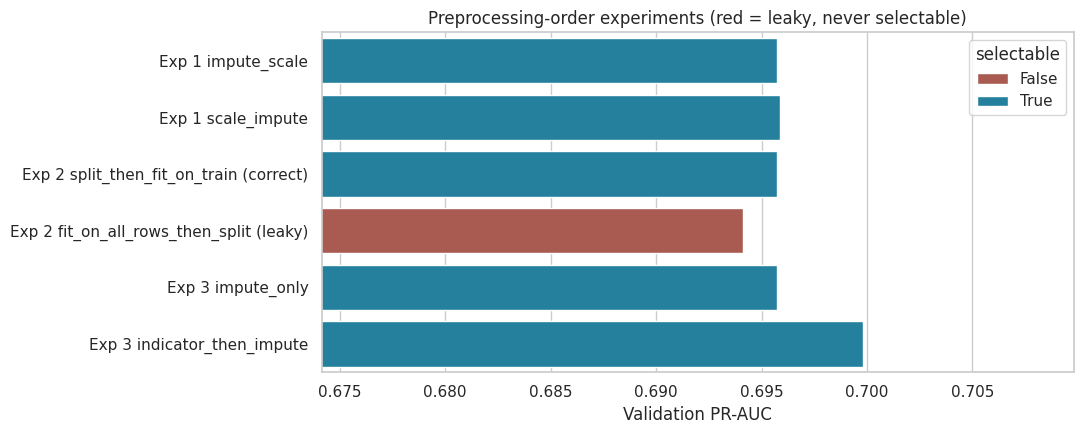

**Selected preprocessing (validation only):** numeric order `impute_scale`, missing indicators `True`. Rule: start from the simplest pipeline (impute -> scale, no indicators) and switch only when a valid variant improves validation PR-AUC by more than 0.002. Gaps: order -0.0001, indicators +0.0041; the leaky order (-0.0016) is excluded by construction. All models below use this configuration.

In [23]:
section("C.6 Preprocessing decision (validation only; the leaky variant is not selectable)")
experiments = pd.concat([exp1_df, exp2_df, exp3_df], ignore_index=True)
experiments["selectable"] = ~experiments["variant"].str.contains("leaky")
display(experiments[["experiment", "variant", "selectable", "roc_auc", "pr_auc", "precision", "recall", "f1", "threshold"]].round(4))

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=experiments.assign(label=lambda d: d["experiment"].str[:5] + " " + d["variant"]), y="label", x="pr_auc", hue="selectable",
            dodge=False, palette={True: "#118ab2", False: "#b85042"}, ax=ax)
ax.set(xlim=(experiments["pr_auc"].min() - 0.02, experiments["pr_auc"].max() + 0.01), xlabel="Validation PR-AUC", ylabel="",
       title="Preprocessing-order experiments (red = leaky, never selectable)")
show_fig("C_preprocessing_experiments")

TOLERANCE = 0.002          # smaller differences are within noise on the validation seasons; otherwise keep the simplest pipeline
PREPROCESSING["order"] = "scale_impute" if exp1_gap < -TOLERANCE else "impute_scale"
PREPROCESSING["add_indicator"] = bool(exp3_gap > TOLERANCE)
record("preprocessing", f"**Selected preprocessing (validation only):** numeric order `{PREPROCESSING['order']}`, missing indicators `{PREPROCESSING['add_indicator']}`. Rule: start from the simplest pipeline "
       f"(impute -> scale, no indicators) and switch only when a valid variant improves validation PR-AUC by more than {TOLERANCE}. Gaps: order {exp1_gap:+.4f}, indicators {exp3_gap:+.4f}; "
       f"the leaky order ({exp2_gap:+.4f}) is excluded by construction. All models below use this configuration.")

In [24]:
section("C.7 Model registry: same rows, same features, same preprocessing for every model")
registry = {}

def register(name, pipe, factory, params=None):
    """Store a fitted pipeline with its probabilities on every split and a validation-chosen threshold."""
    proba = {s: pipe.predict_proba(xs)[:, 1] for s, (xs, _) in SPLITS.items()}
    registry[name] = {"pipe": pipe, "factory": factory, "params": params, "proba": proba,
                      "threshold": choose_threshold(y_val, proba["validation"])}

def tune(name, make_estimator, grid):
    """Grid search scored by validation PR-AUC (the test split is never touched); registers the best model."""
    best, rows = None, []
    for params in ParameterGrid(grid):
        pipe = build_pipeline(make_estimator(**params)).fit(X_train, y_train)
        proba_val = pipe.predict_proba(X_val)[:, 1]
        rows.append({**params, "validation_pr_auc": average_precision_score(y_val, proba_val), "validation_roc_auc": roc_auc_score(y_val, proba_val)})
        if best is None or rows[-1]["validation_pr_auc"] > best[0]:
            best = (rows[-1]["validation_pr_auc"], pipe, params)
    register(name, best[1], lambda p=best[2]: make_estimator(**p), best[2])
    return pd.DataFrame(rows).sort_values("validation_pr_auc", ascending=False).reset_index(drop=True)

def metrics_table(names):
    return pd.DataFrame([{"model": n, "split": s, **score(ys, registry[n]["proba"][s], registry[n]["threshold"])}
                         for n in names for s, (_, ys) in SPLITS.items()])
print(f"train {len(X_train):,} | validation {len(X_val):,} | test {len(X_test):,} rows; {len(feature_columns)} raw features; preprocessing {PREPROCESSING}")

#### C.7 Model registry: same rows, same features, same preprocessing for every model

train 24,109 | validation 1,200 | test 1,359 rows; 34 raw features; preprocessing {'order': 'impute_scale', 'add_indicator': True}


In [25]:
section("C.8 Attempt 1: baseline logistic regression")
BASELINE = "Logistic Regression (baseline)"
register(BASELINE, build_pipeline(lr()).fit(X_train, y_train), lr)
display(metrics_table([BASELINE]).round(4))
display(Markdown("Fixed settings (`C=1`, L2, balanced class weights so the rare podium class is not ignored). It is the reference every other model must beat. "
                 "*Limitations:* linear and additive in log-odds, so the steep jump between grid P3 and P4 and car-by-grid interactions are only approximated."))

#### C.8 Attempt 1: baseline logistic regression

,model,split,roc_auc,pr_auc,f1,precision,recall,threshold
0,Logistic Regression (baseline),train,0.9081,0.5534,0.5597,0.5483,0.5716,0.81
1,Logistic Regression (baseline),validation,0.9358,0.6998,0.7179,0.6667,0.7778,0.81
2,Logistic Regression (baseline),test,0.9323,0.6964,0.6524,0.6343,0.6716,0.81


Fixed settings (`C=1`, L2, balanced class weights so the rare podium class is not ignored). It is the reference every other model must beat. *Limitations:* linear and additive in log-odds, so the steep jump between grid P3 and P4 and car-by-grid interactions are only approximated.

In [26]:
section("C.9 Attempt 2: random forest (tuned on validation PR-AUC)")
RF = "Random Forest"
rf_grid = tune(RF, lambda min_samples_leaf, max_features: RandomForestClassifier(
    n_estimators=300, min_samples_leaf=min_samples_leaf, max_features=max_features, class_weight="balanced_subsample",
    random_state=RANDOM_STATE, n_jobs=-1), {"min_samples_leaf": [3, 10, 25], "max_features": ["sqrt", 0.1]})
display(rf_grid.round(4)); display(metrics_table([RF]).round(4))
display(Markdown("Bagged deep trees capture non-linearities (grid P1-P3 vs P4+) and interactions without manual crosses. "
                 "*Limitations:* cannot extrapolate beyond the training range (for example new points scales), probabilities are poorly calibrated, and it overfits training rows more than linear models."))

#### C.9 Attempt 2: random forest (tuned on validation PR-AUC)

,max_features,min_samples_leaf,validation_pr_auc,validation_roc_auc
0,sqrt,3,0.7564,0.9403
1,0.1,3,0.7533,0.9399
2,0.1,10,0.7507,0.9408
3,sqrt,10,0.7487,0.9388
4,0.1,25,0.7428,0.9391
5,sqrt,25,0.7367,0.9378


,model,split,roc_auc,pr_auc,f1,precision,recall,threshold
0,Random Forest,train,0.9883,0.9229,0.8267,0.8297,0.8236,0.63
1,Random Forest,validation,0.9403,0.7564,0.7348,0.7308,0.7389,0.63
2,Random Forest,test,0.9340,0.6933,0.6462,0.6774,0.6176,0.63


Bagged deep trees capture non-linearities (grid P1-P3 vs P4+) and interactions without manual crosses. *Limitations:* cannot extrapolate beyond the training range (for example new points scales), probabilities are poorly calibrated, and it overfits training rows more than linear models.

In [27]:
section("C.10 Attempt 3: histogram gradient boosting (tuned on validation PR-AUC)")
HGB = "Gradient Boosting (HistGB)"
hgb_grid = tune(HGB, lambda learning_rate, max_leaf_nodes, l2_regularization: HistGradientBoostingClassifier(
    learning_rate=learning_rate, max_leaf_nodes=max_leaf_nodes, l2_regularization=l2_regularization, max_iter=500, early_stopping=True,
    validation_fraction=0.1, n_iter_no_change=20, class_weight="balanced", random_state=RANDOM_STATE),
    {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [15, 31], "l2_regularization": [0.0, 1.0]})
display(hgb_grid.round(4)); display(metrics_table([HGB]).round(4))
display(Markdown("Boosted shallow trees; the number of rounds is controlled by early stopping on an internal 10% hold-out drawn from the **training rows only**, so validation stays untouched. "
                 "*Limitations:* sensitive to learning rate and tree size, cannot extrapolate, and the internal hold-out is a random (not chronological) slice of training data."))

#### C.10 Attempt 3: histogram gradient boosting (tuned on validation PR-AUC)

,l2_regularization,learning_rate,max_leaf_nodes,validation_pr_auc,validation_roc_auc
0,0.0,0.03,15,0.7466,0.9398
1,0.0,0.03,31,0.7420,0.9379
2,1.0,0.03,15,0.7411,0.9400
3,1.0,0.03,31,0.7394,0.9389
4,0.0,0.10,15,0.7310,0.9396
5,1.0,0.10,15,0.7305,0.9382
6,0.0,0.10,31,0.7261,0.9366
7,1.0,0.10,31,0.7221,0.9366


,model,split,roc_auc,pr_auc,f1,precision,recall,threshold
0,Gradient Boosting (HistGB),train,0.9218,0.5966,0.5551,0.5883,0.5254,0.83
1,Gradient Boosting (HistGB),validation,0.9398,0.7466,0.7346,0.7098,0.7611,0.83
2,Gradient Boosting (HistGB),test,0.9371,0.7023,0.6836,0.6463,0.7255,0.83


Boosted shallow trees; the number of rounds is controlled by early stopping on an internal 10% hold-out drawn from the **training rows only**, so validation stays untouched. *Limitations:* sensitive to learning rate and tree size, cannot extrapolate, and the internal hold-out is a random (not chronological) slice of training data.

#### C.11 Evaluation: ROC-AUC, PR-AUC, F1, precision, recall on train / validation / test

,model,split,roc_auc,pr_auc,f1,precision,recall,threshold
0,Logistic Regression (baseline),train,0.9081,0.5534,0.5597,0.5483,0.5716,0.81
1,Logistic Regression (baseline),validation,0.9358,0.6998,0.7179,0.6667,0.7778,0.81
2,Logistic Regression (baseline),test,0.9323,0.6964,0.6524,0.6343,0.6716,0.81
3,Random Forest,train,0.9883,0.9229,0.8267,0.8297,0.8236,0.63
4,Random Forest,validation,0.9403,0.7564,0.7348,0.7308,0.7389,0.63
5,Random Forest,test,0.9340,0.6933,0.6462,0.6774,0.6176,0.63
6,Gradient Boosting (HistGB),train,0.9218,0.5966,0.5551,0.5883,0.5254,0.83
7,Gradient Boosting (HistGB),validation,0.9398,0.7466,0.7346,0.7098,0.7611,0.83
8,Gradient Boosting (HistGB),test,0.9371,0.7023,0.6836,0.6463,0.7255,0.83


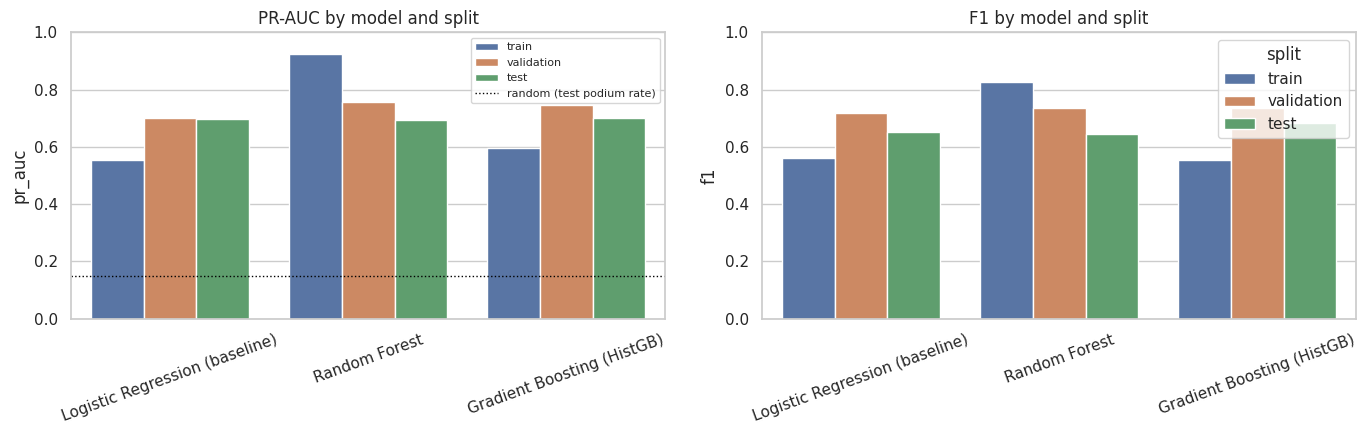

**Metrics.** Primary: **PR-AUC**. Only about 12%-15% of rows are podiums, so ROC-AUC is inflated by the many easy negatives, while PR-AUC measures how well the true podium finishers are ranked above everyone else (a random ranker scores the podium rate, 0.150 on test). Secondary: **F1** at the validation-chosen threshold, because a companion app must make a yes/no call; validation F1 is slightly optimistic since the threshold was tuned on it. ROC-AUC, precision and recall are reported alongside. Best statistical model on validation PR-AUC: **Random Forest** (0.7564; gain over baseline +0.0566); its test PR-AUC is 0.6933 against 0.6964 for the baseline. On the unseen test seasons the best PR-AUC belongs to **Gradient Boosting (HistGB)** (0.7023), not the validation-selected model (0.6933); the choice is deliberately not changed, because selecting on test would turn it into a second validation set.

In [28]:
section("C.11 Evaluation: ROC-AUC, PR-AUC, F1, precision, recall on train / validation / test")
STAT_MODELS = [BASELINE, RF, HGB]
METRICS = ["roc_auc", "pr_auc", "f1", "precision", "recall"]

def plot_metric_bars(metrics, name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for ax, metric in zip(axes, ["pr_auc", "f1"]):
        sns.barplot(data=metrics, x="model", y=metric, hue="split", hue_order=["train", "validation", "test"], ax=ax)
        ax.set(title=f"{metric.upper().replace('_', '-')} by model and split", xlabel="", ylim=(0, 1))
        ax.tick_params(axis="x", rotation=20)
    axes[0].axhline(float(y_test.mean()), color="black", linestyle=":", linewidth=1, label="random (test podium rate)")
    axes[0].legend(fontsize=8)
    show_fig(name)

stat_metrics = metrics_table(STAT_MODELS)
display(stat_metrics.round(4))
plot_metric_bars(stat_metrics, "C_statistical_model_comparison")
val_pr = stat_metrics[stat_metrics["split"] == "validation"].set_index("model")["pr_auc"]
BEST_STAT = val_pr.idxmax()
test_pr = stat_metrics[stat_metrics["split"] == "test"].set_index("model")["pr_auc"]
caveat = (f" On the unseen test seasons the best PR-AUC belongs to **{test_pr.idxmax()}** ({test_pr.max():.4f}), not the validation-selected model ({test_pr[BEST_STAT]:.4f}); "
          "the choice is deliberately not changed, because selecting on test would turn it into a second validation set.") if test_pr.idxmax() != BEST_STAT else ""
record("models", f"**Metrics.** Primary: **PR-AUC**. Only about {min(y_train.mean(), y_val.mean(), y_test.mean()):.0%}-{max(y_train.mean(), y_val.mean(), y_test.mean()):.0%} of rows are podiums, so ROC-AUC is inflated by the many easy negatives, while PR-AUC measures how well the "
       f"true podium finishers are ranked above everyone else (a random ranker scores the podium rate, {y_test.mean():.3f} on test). Secondary: **F1** at the validation-chosen threshold, because a "
       "companion app must make a yes/no call; validation F1 is slightly optimistic since the threshold was tuned on it. ROC-AUC, precision and recall are reported alongside. "
       f"Best statistical model on validation PR-AUC: **{BEST_STAT}** ({val_pr[BEST_STAT]:.4f}; gain over baseline {val_pr[BEST_STAT] - val_pr[BASELINE]:+.4f}); its test PR-AUC is "
       f"{test_pr[BEST_STAT]:.4f} against {test_pr[BASELINE]:.4f} for the baseline.{caveat}")

#### C.12 Feature-group ablation: remove one group, retrain, compare

,model,variant,validation_pr_auc,validation_f1,test_pr_auc,test_f1,validation_pr_auc_delta,test_pr_auc_delta
0,Logistic Regression (baseline),full model,0.6998,0.7179,0.6964,0.6524,0.0000,0.0000
1,Logistic Regression (baseline),drop grid,0.7038,0.7111,0.6826,0.6535,0.0040,-0.0138
2,Logistic Regression (baseline),drop qualifying,0.6878,0.7258,0.6841,0.6394,-0.0120,-0.0124
3,Logistic Regression (baseline),drop standings,0.6912,0.7273,0.7041,0.6605,-0.0086,0.0077
4,Logistic Regression (baseline),drop form,0.6942,0.7353,0.6616,0.6555,-0.0056,-0.0348
5,Logistic Regression (baseline),drop context,0.7297,0.7190,0.7127,0.6692,0.0299,0.0163
6,Logistic Regression (baseline),add driverId + constructorId,0.6740,0.7150,0.6691,0.6078,-0.0258,-0.0273
7,Random Forest,full model,0.7564,0.7348,0.6933,0.6462,0.0000,0.0000
8,Random Forest,drop grid,0.7458,0.7258,0.6709,0.6316,-0.0106,-0.0225
9,Random Forest,drop qualifying,0.7191,0.7253,0.6687,0.6147,-0.0373,-0.0246


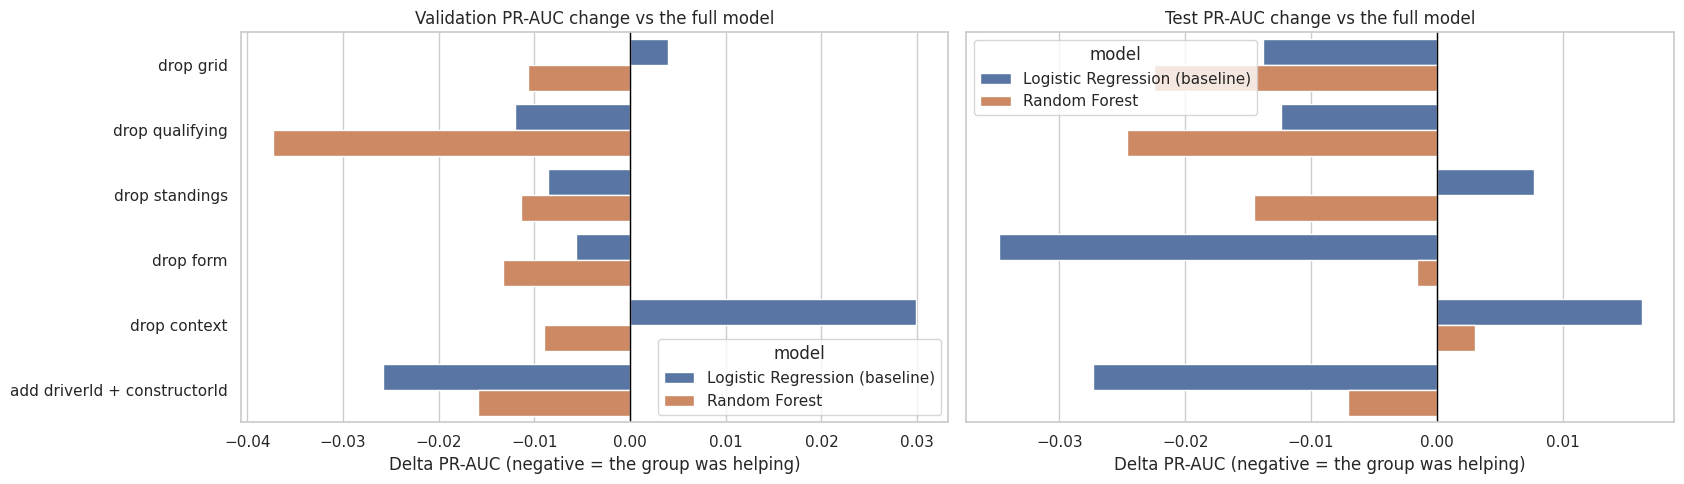

**Ablation (validation PR-AUC, model retrained for every variant).** for Logistic Regression (baseline), removing `qualifying` hurts validation PR-AUC most (-0.0120); for Random Forest, removing `qualifying` hurts validation PR-AUC most (-0.0373). Adding driverId + constructorId back changes validation PR-AUC by -0.0258 (Logistic Regression (baseline)), -0.0158 (Random Forest) (test: -0.0273, -0.0070); this is the evidence for the entity-ID decision in B.1, which is made on the validation numbers. Grid and qualifying overlap (grid is mostly qualifying order plus penalties) and so do form and standings, so removing one group alone costs less than its importance suggests because the other covers for it. A positive delta means the model generalised better without that group.

In [29]:
section("C.12 Feature-group ablation: remove one group, retrain, compare")
ID_FEATURES = ["driverId", "constructorId"]
X_all = X.assign(**{c: modeling_data[c].astype(str) for c in ID_FEATURES})            # includes the IDs so the 'add back' variant can be tested

variants = {"full model": (numeric_features, categorical_features)}
for group, cols in FEATURE_GROUPS.items():
    variants[f"drop {group}"] = ([c for c in numeric_features if c not in cols], [c for c in categorical_features if c not in cols])
if DROP_ENTITY_IDS:
    variants["add driverId + constructorId"] = (numeric_features, categorical_features + ID_FEATURES)

ablation_rows = []
for model_name in dict.fromkeys([BASELINE, BEST_STAT]):
    for label, (num, cat) in variants.items():
        cols = num + cat
        pipe = build_pipeline(registry[model_name]["factory"](), num, cat).fit(X_all.loc[X_train.index, cols], y_train)
        proba = {s: pipe.predict_proba(X_all.loc[xs.index, cols])[:, 1] for s, (xs, _) in SPLITS.items()}
        threshold = choose_threshold(y_val, proba["validation"])
        val_m, test_m = score(y_val, proba["validation"], threshold), score(y_test, proba["test"], threshold)
        ablation_rows.append({"model": model_name, "variant": label, "validation_pr_auc": val_m["pr_auc"], "validation_f1": val_m["f1"],
                              "test_pr_auc": test_m["pr_auc"], "test_f1": test_m["f1"]})
ablation_df = pd.DataFrame(ablation_rows)
full = ablation_df[ablation_df["variant"] == "full model"].set_index("model")
ablation_df["validation_pr_auc_delta"] = ablation_df["validation_pr_auc"] - ablation_df["model"].map(full["validation_pr_auc"])
ablation_df["test_pr_auc_delta"] = ablation_df["test_pr_auc"] - ablation_df["model"].map(full["test_pr_auc"])
display(ablation_df.round(4))

plot_df = ablation_df[ablation_df["variant"] != "full model"]
fig, axes = plt.subplots(1, 2, figsize=(17, 5), sharey=True)
for ax, sp in zip(axes, ["validation", "test"]):
    sns.barplot(data=plot_df, y="variant", x=f"{sp}_pr_auc_delta", hue="model", ax=ax)
    ax.axvline(0, color="black", linewidth=1)
    ax.set(title=f"{sp.title()} PR-AUC change vs the full model", xlabel="Delta PR-AUC (negative = the group was helping)", ylabel="")
show_fig("C_feature_group_ablation")

bits = []
for model_name, part in plot_df[~plot_df["variant"].str.startswith("add")].groupby("model", sort=False):
    worst = part.sort_values("validation_pr_auc_delta").iloc[0]
    bits.append(f"for {model_name}, removing `{worst['variant'].replace('drop ', '')}` hurts validation PR-AUC most ({worst['validation_pr_auc_delta']:+.4f})")
id_rows = plot_df[plot_df["variant"] == "add driverId + constructorId"]
id_text = ("Adding driverId + constructorId back changes validation PR-AUC by " + ", ".join(
    f"{r.validation_pr_auc_delta:+.4f} ({r.model})" for r in id_rows.itertuples()) + " (test: " + ", ".join(
    f"{r.test_pr_auc_delta:+.4f}" for r in id_rows.itertuples()) + "); this is the evidence for the entity-ID decision in B.1, which is made on the validation numbers.") if len(id_rows) else ""
record("ablation", "**Ablation (validation PR-AUC, model retrained for every variant).** " + "; ".join(bits) + ". " + id_text +
       " Grid and qualifying overlap (grid is mostly qualifying order plus penalties) and so do form and standings, so removing one group alone costs less than its importance suggests because the other "
       "covers for it. A positive delta means the model generalised better without that group.")

#### C.13 Global permutation importance (validation seasons, PR-AUC drop, raw features)

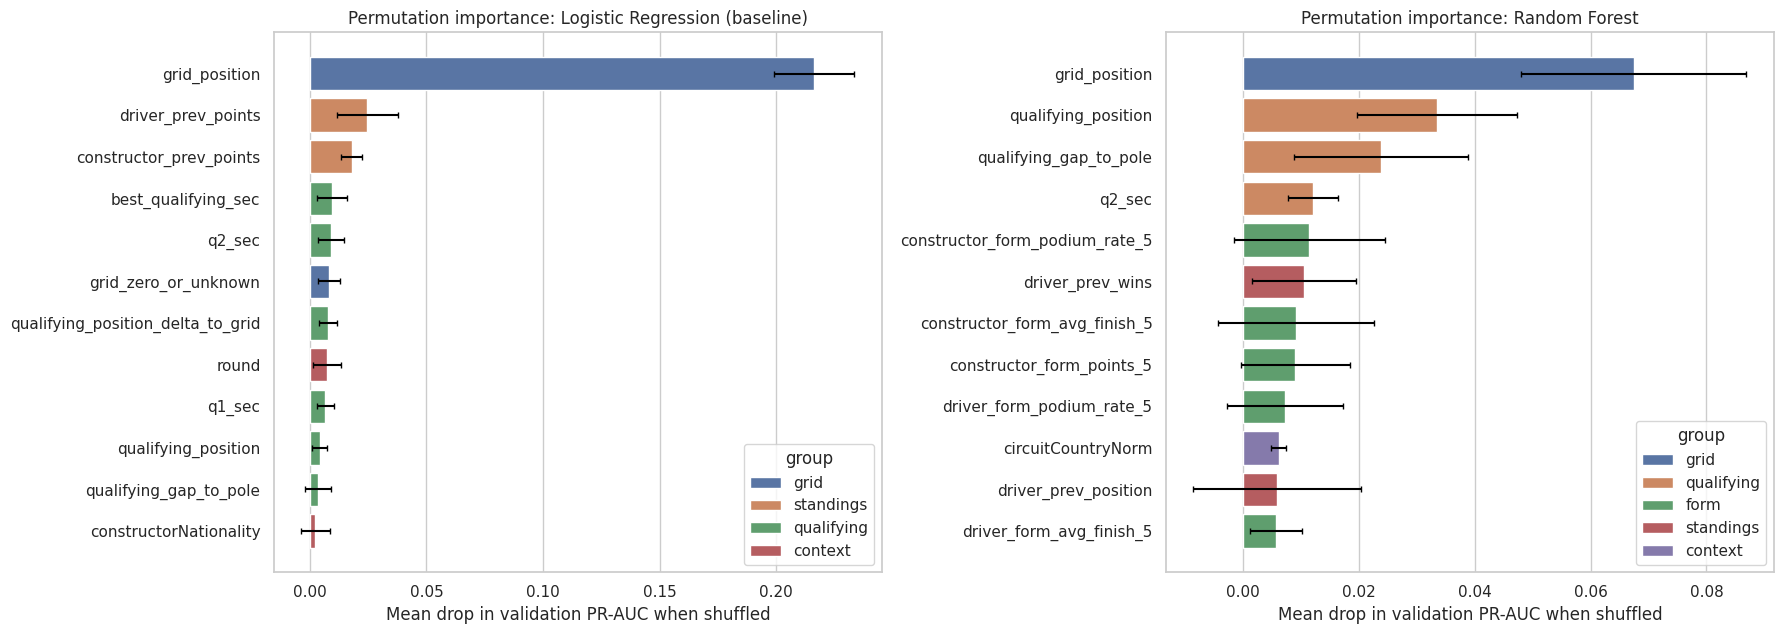

**Logistic Regression (baseline): top 8**

,feature,group,importance_mean,importance_std
0,grid_position,grid,0.2162,0.0173
1,driver_prev_points,standings,0.0246,0.0130
2,constructor_prev_points,standings,0.0180,0.0045
3,best_qualifying_sec,qualifying,0.0095,0.0063
4,q2_sec,qualifying,0.0092,0.0055
5,grid_zero_or_unknown,grid,0.0082,0.0048
6,qualifying_position_delta_to_grid,qualifying,0.0078,0.0038
7,round,context,0.0073,0.0059


**Random Forest: top 8**

,feature,group,importance_mean,importance_std
0,grid_position,grid,0.0674,0.0195
1,qualifying_position,qualifying,0.0335,0.0138
2,qualifying_gap_to_pole,qualifying,0.0238,0.0150
3,q2_sec,qualifying,0.0120,0.0043
4,constructor_form_podium_rate_5,form,0.0114,0.0130
5,driver_prev_wins,standings,0.0105,0.0090
6,constructor_form_avg_finish_5,form,0.0091,0.0135
7,constructor_form_points_5,form,0.0090,0.0094


**Permutation importance** (shuffle one raw feature at a time through the full pipeline, measure the validation PR-AUC drop). Logistic Regression (baseline) relies most on `grid_position`, `driver_prev_points`, `constructor_prev_points`. Random Forest relies most on `grid_position`, `qualifying_position`, `qualifying_gap_to_pole`. Correlated features share credit (shuffling `grid_position` leaves `qualifying_position` intact), so single-feature importances understate how much the model relies on 'where the car starts'. **This is model reliance, not causality:** a high `constructor_form_podium_rate_5` does not make a car faster, it marks a car that already is.

In [30]:
section("C.13 Global permutation importance (validation seasons, PR-AUC drop, raw features)")
perm_results = {}
for model_name in dict.fromkeys([BASELINE, BEST_STAT]):
    result = permutation_importance(registry[model_name]["pipe"], X_val, y_val, scoring="average_precision", n_repeats=5,
                                    random_state=RANDOM_STATE, n_jobs=-1)
    perm_results[model_name] = (pd.DataFrame({"feature": feature_columns, "group": [group_of[f] for f in feature_columns],
                                              "importance_mean": result.importances_mean, "importance_std": result.importances_std})
                                .sort_values("importance_mean", ascending=False).reset_index(drop=True))
fig, axes = plt.subplots(1, len(perm_results), figsize=(9 * len(perm_results), 6.5), squeeze=False)
for ax, (model_name, table) in zip(axes[0], perm_results.items()):
    top = table.head(12)
    sns.barplot(data=top, x="importance_mean", y="feature", hue="group", dodge=False, ax=ax)
    ax.errorbar(top["importance_mean"], range(len(top)), xerr=top["importance_std"], fmt="none", ecolor="black", capsize=2)
    ax.set(title=f"Permutation importance: {model_name}", xlabel="Mean drop in validation PR-AUC when shuffled", ylabel="")
show_fig("C_permutation_importance")
for model_name, table in perm_results.items():
    display(Markdown(f"**{model_name}: top 8**")); display(table.head(8).round(4))
record("importance", "**Permutation importance** (shuffle one raw feature at a time through the full pipeline, measure the validation PR-AUC drop). " + " ".join(
    f"{m} relies most on `{'`, `'.join(t['feature'].head(3))}`." for m, t in perm_results.items()) +
    " Correlated features share credit (shuffling `grid_position` leaves `qualifying_position` intact), so single-feature importances understate how much the model relies on 'where the car starts'. "
    "**This is model reliance, not causality:** a high `constructor_form_podium_rate_5` does not make a car faster, it marks a car that already is.")

# Part D: Neural network, SHAP explanations, inference function, integrated report

The neural network uses the same rows, features, chronological split and leakage-safe preprocessing as the statistical models. Explanations describe what the model relies on; they are **not** causal effects.

In [31]:
section("D.1 Neural network (one or two hidden layers): architecture and regularisation tuned on validation PR-AUC")
NN = "Neural Network (MLP)"
nn_grid = tune(NN, lambda hidden_layer_sizes, alpha: MLPClassifier(
    hidden_layer_sizes=hidden_layer_sizes, alpha=alpha, early_stopping=True, validation_fraction=0.1, n_iter_no_change=10,
    max_iter=200, random_state=RANDOM_STATE), {"hidden_layer_sizes": [(32,), (64,), (64, 32)], "alpha": [1e-4, 1e-2]})
display(nn_grid.round(4)); display(metrics_table([NN]).round(4))
nn_best = registry[NN]["params"]
record("nn", f"**Neural network.** Candidates: one hidden layer (32 or 64 ReLU units) or two (64-32), each with L2 strength 1e-4 or 1e-2; selected by validation PR-AUC: hidden layers "
       f"{nn_best['hidden_layer_sizes']}, alpha {nn_best['alpha']}. Early stopping uses an internal 10% hold-out of the **training rows**, and the F1 threshold is chosen on validation only. "
       "*Limitations:* scikit-learn's MLP has no class weights, so the rare podium class is handled only through the decision threshold; the internal early-stopping hold-out is a random "
       "(not chronological) slice of training data; results depend on the random seed; and one-hot inputs make the network sensitive to rarely seen categories.")

#### D.1 Neural network (one or two hidden layers): architecture and regularisation tuned on validation PR-AUC

,alpha,hidden_layer_sizes,validation_pr_auc,validation_roc_auc
0,0.0100,"(64,)",0.7569,0.9370
1,0.0001,"(64, 32)",0.7375,0.9311
2,0.0100,"(64, 32)",0.7358,0.9318
3,0.0001,"(32,)",0.7335,0.9371
4,0.0100,"(32,)",0.7262,0.9357
5,0.0001,"(64,)",0.7214,0.9304


,model,split,roc_auc,pr_auc,f1,precision,recall,threshold
0,Neural Network (MLP),train,0.917,0.6061,0.5913,0.5505,0.6387,0.34
1,Neural Network (MLP),validation,0.937,0.7569,0.7190,0.6605,0.7889,0.34
2,Neural Network (MLP),test,0.932,0.6826,0.6481,0.5763,0.7402,0.34


**Neural network.** Candidates: one hidden layer (32 or 64 ReLU units) or two (64-32), each with L2 strength 1e-4 or 1e-2; selected by validation PR-AUC: hidden layers (64,), alpha 0.01. Early stopping uses an internal 10% hold-out of the **training rows**, and the F1 threshold is chosen on validation only. *Limitations:* scikit-learn's MLP has no class weights, so the rare podium class is handled only through the decision threshold; the internal early-stopping hold-out is a random (not chronological) slice of training data; results depend on the random seed; and one-hot inputs make the network sensitive to rarely seen categories.

#### D.2 Final comparison of all four models and selection of the model to explain

,model,split,roc_auc,pr_auc,f1,precision,recall,threshold
0,Logistic Regression (baseline),train,0.9081,0.5534,0.5597,0.5483,0.5716,0.81
1,Logistic Regression (baseline),validation,0.9358,0.6998,0.7179,0.6667,0.7778,0.81
2,Logistic Regression (baseline),test,0.9323,0.6964,0.6524,0.6343,0.6716,0.81
3,Random Forest,train,0.9883,0.9229,0.8267,0.8297,0.8236,0.63
4,Random Forest,validation,0.9403,0.7564,0.7348,0.7308,0.7389,0.63
5,Random Forest,test,0.9340,0.6933,0.6462,0.6774,0.6176,0.63
6,Gradient Boosting (HistGB),train,0.9218,0.5966,0.5551,0.5883,0.5254,0.83
7,Gradient Boosting (HistGB),validation,0.9398,0.7466,0.7346,0.7098,0.7611,0.83
8,Gradient Boosting (HistGB),test,0.9371,0.7023,0.6836,0.6463,0.7255,0.83
9,Neural Network (MLP),train,0.9170,0.6061,0.5913,0.5505,0.6387,0.34


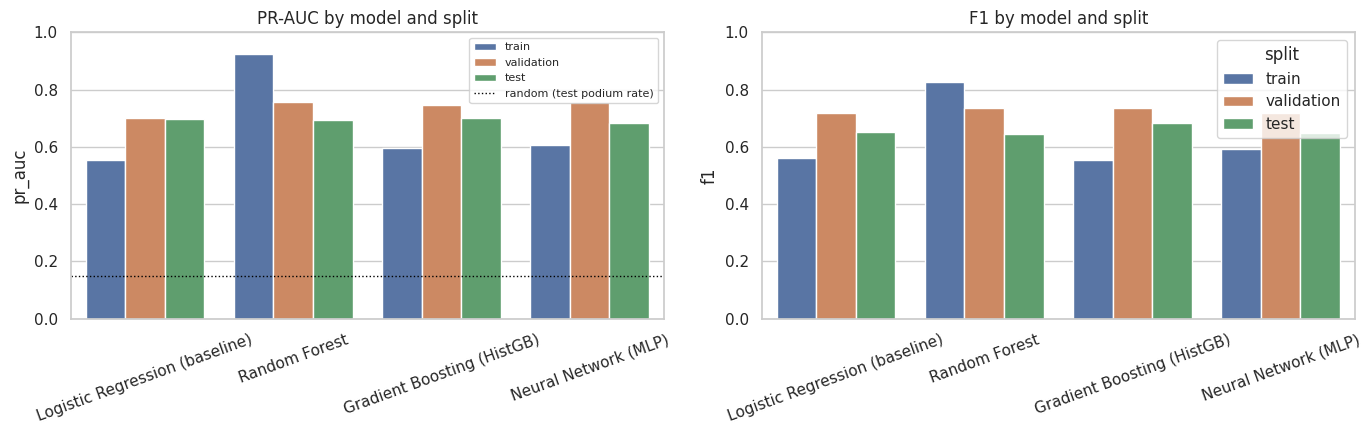

**Model selection.** Compared with the Part C baseline and the tree models, the neural network reaches validation PR-AUC 0.7569 (baseline 0.6998, random forest 0.7564, gradient boosting 0.7466). Selected by validation PR-AUC: **Neural Network (MLP)**; unseen-test PR-AUC 0.6826, F1 0.6481 (precision 0.576, recall 0.740) at the validation-chosen threshold 0.34. The test seasons were not used for any model, threshold or preprocessing choice. Four distinct modeling attempts were made (baseline logistic regression, random forest, gradient boosting, neural network).

,split,season,rows,podium_rate,pr_auc
0,validation,2019,420,0.1500,0.7765
1,validation,2020,340,0.1500,0.7459
2,validation,2021,440,0.1500,0.7630
3,test,2022,440,0.1500,0.6690
4,test,2023,440,0.1500,0.7459
5,test,2024,479,0.1503,0.6289


**Era sensitivity of the selected model** (PR-AUC per season, table above): validation seasons range 0.746-0.777, test seasons 0.629-0.746. The training window spans very different eras (field sizes, points systems, qualifying formats, and no qualifying data before the table starts), so performance should be read per era, not only as one pooled number.

In [32]:
section("D.2 Final comparison of all four models and selection of the model to explain")
ALL_MODELS = [BASELINE, RF, HGB, NN]
final_metrics = metrics_table(ALL_MODELS)
display(final_metrics.round(4))
plot_metric_bars(final_metrics, "D_final_model_comparison")
val_pr = final_metrics[final_metrics["split"] == "validation"].set_index("model")["pr_auc"]
FINAL_MODEL = val_pr.idxmax()                              # selected on validation PR-AUC only
final_test = final_metrics[(final_metrics["split"] == "test")].set_index("model")
record("final_models", f"**Model selection.** Compared with the Part C baseline and the tree models, the neural network reaches validation PR-AUC {val_pr[NN]:.4f} "
       f"(baseline {val_pr[BASELINE]:.4f}, random forest {val_pr[RF]:.4f}, gradient boosting {val_pr[HGB]:.4f}). Selected by validation PR-AUC: **{FINAL_MODEL}**; "
       f"unseen-test PR-AUC {final_test.loc[FINAL_MODEL, 'pr_auc']:.4f}, F1 {final_test.loc[FINAL_MODEL, 'f1']:.4f} (precision {final_test.loc[FINAL_MODEL, 'precision']:.3f}, "
       f"recall {final_test.loc[FINAL_MODEL, 'recall']:.3f}) at the validation-chosen threshold {registry[FINAL_MODEL]['threshold']:.2f}. The test seasons were not used for any model, "
       "threshold or preprocessing choice. Four distinct modeling attempts were made (baseline logistic regression, random forest, gradient boosting, neural network).")

final_pipe = registry[FINAL_MODEL]["pipe"]
season_rows = []
for sp, (xs, ys) in [("validation", SPLITS["validation"]), ("test", SPLITS["test"])]:
    for yr, idx in modeling_data.loc[xs.index].groupby("year").groups.items():
        season_rows.append({"split": sp, "season": int(yr), "rows": len(idx), "podium_rate": ys.loc[idx].mean(),
                            "pr_auc": average_precision_score(ys.loc[idx], registry[FINAL_MODEL]["proba"][sp][xs.index.get_indexer(idx)])})
era_table = pd.DataFrame(season_rows)
display(era_table.round(4))
record("era", f"**Era sensitivity of the selected model** (PR-AUC per season, table above): validation seasons range {era_table.query('split == \"validation\"')['pr_auc'].min():.3f}-"
       f"{era_table.query('split == \"validation\"')['pr_auc'].max():.3f}, test seasons {era_table.query('split == \"test\"')['pr_auc'].min():.3f}-{era_table.query('split == \"test\"')['pr_auc'].max():.3f}. "
       "The training window spans very different eras (field sizes, points systems, qualifying formats, and no qualifying data before the table starts), so performance should be read per era, "
       "not only as one pooled number.")

#### D.3 SHAP explanations for the selected model (global and local, on raw pre-race features)

PermutationExplainer explainer: 101it [00:22,  3.67it/s]                         


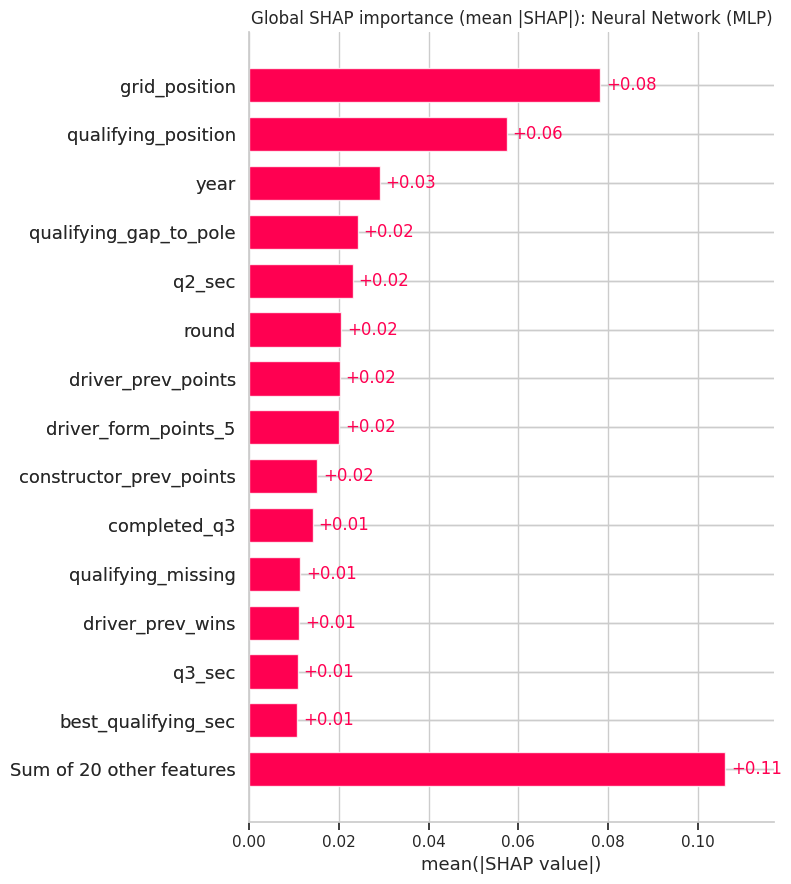

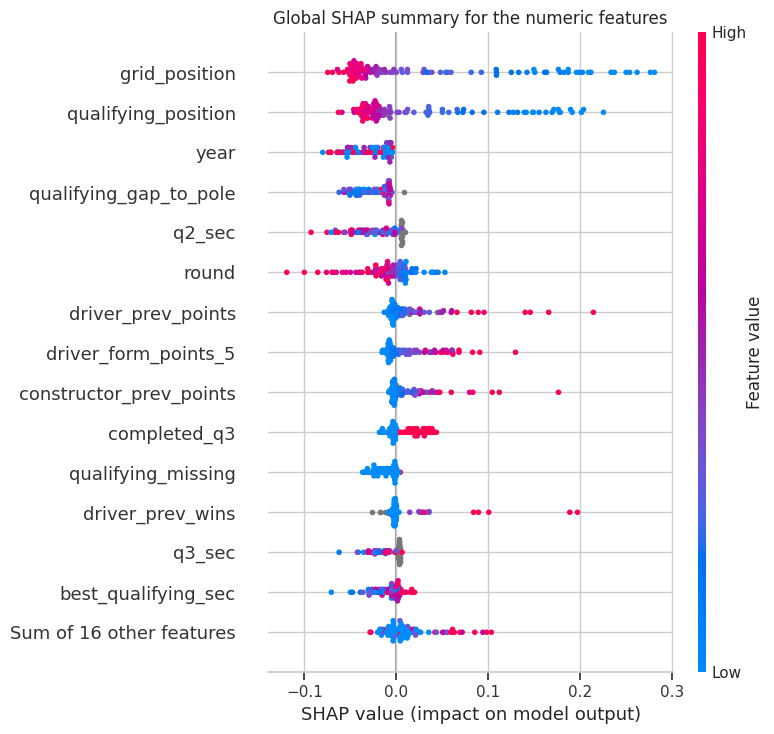

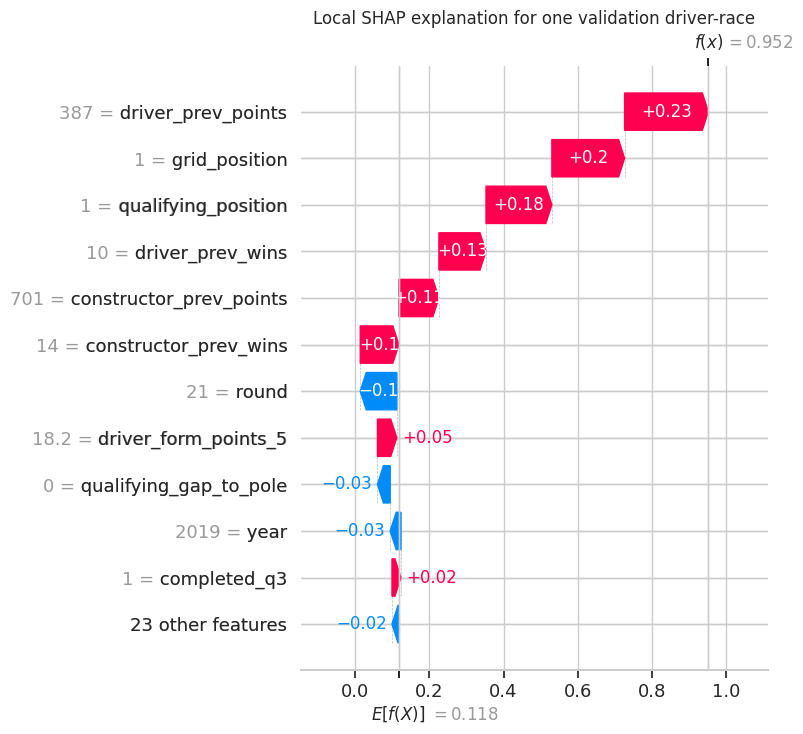

,feature,value,shap_value
18,driver_prev_points,387.0,0.225716
2,grid_position,1.0,0.195975
4,qualifying_position,1.0,0.177436
20,driver_prev_wins,10.0,0.126842
21,constructor_prev_points,701.0,0.107832
23,constructor_prev_wins,14.0,0.104169
1,round,21,-0.098480
26,driver_form_points_5,18.2,0.052083


**SHAP (model-agnostic permutation explainer on raw features; model = Neural Network (MLP)).** Globally the model leans most on `grid_position`, `qualifying_position`, `year`, `qualifying_gap_to_pole`, `q2_sec` (figures above; these should be read together with the permutation importance in Part C). Local example: race 1030, driver 1, season 2019: predicted podium probability 0.95 (actual outcome: podium); the waterfall shows which features pushed this prediction above or below the average prediction. SHAP values describe how the **model** uses its inputs on these rows; they are associations learned from history, **not causal effects** of any feature on finishing position.

In [33]:
section("D.3 SHAP explanations for the selected model (global and local, on raw pre-race features)")
try:
    import shap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

levels = {c: sorted(X[c].dropna().unique()) for c in categorical_features}
level_code = {c: {v: float(i) for i, v in enumerate(levels[c])} for c in categorical_features}

def encode(frame):
    """Raw features as a float matrix (categoricals as level codes, NaN kept) because SHAP's masker needs numeric arrays."""
    out = frame[feature_columns].copy()
    for c in categorical_features:
        out[c] = out[c].map(level_code[c]).astype(float)
    return out.to_numpy(dtype=float)

def predict_raw(values):
    """Selected pipeline as a function of the encoded raw matrix, so SHAP attributes to features such as grid_position, not to one-hot columns."""
    frame = pd.DataFrame(values, columns=feature_columns)
    for c in categorical_features:
        frame[c] = [levels[c][int(k)] if not np.isnan(k) else np.nan for k in frame[c]]
    return final_pipe.predict_proba(frame)[:, 1]

background = encode(X_train.sample(50, random_state=RANDOM_STATE))
explain_rows = X_val.sample(min(100, len(X_val)), random_state=RANDOM_STATE)
explainer = shap.Explainer(predict_raw, shap.maskers.Independent(background, max_samples=50), algorithm="permutation", feature_names=feature_columns)
shap_global = explainer(encode(explain_rows), max_evals=6 * len(feature_columns) + 1)

mean_abs = pd.Series(np.abs(shap_global.values).mean(axis=0), index=feature_columns).sort_values(ascending=False)
numeric_idx = [feature_columns.index(c) for c in numeric_features]
shap_numeric = shap.Explanation(values=shap_global.values[:, numeric_idx], base_values=shap_global.base_values,
                                data=explain_rows[numeric_features].to_numpy(dtype=float), feature_names=numeric_features)
plt.figure(); shap.plots.bar(shap_global, max_display=15, show=False); plt.title(f"Global SHAP importance (mean |SHAP|): {FINAL_MODEL}")
show_fig("D_shap_global_bar")
plt.figure(); shap.plots.beeswarm(shap_numeric, max_display=15, show=False); plt.title("Global SHAP summary for the numeric features")
show_fig("D_shap_global_beeswarm")

# Local explanation: the highest-probability driver-race in the validation seasons
local_pos = X_val.index[int(np.argmax(registry[FINAL_MODEL]["proba"]["validation"]))]
local_row = X_val.loc[[local_pos]]
local = explainer(encode(local_row), max_evals=6 * len(feature_columns) + 1)
local = shap.Explanation(values=local.values, base_values=local.base_values, data=local_row.to_numpy(dtype=object), feature_names=feature_columns)
plt.figure(); shap.plots.waterfall(local[0], max_display=12, show=False)
plt.title("Local SHAP explanation for one validation driver-race"); show_fig("D_shap_local_waterfall")
local_table = pd.DataFrame({"feature": feature_columns, "value": local_row.iloc[0].values, "shap_value": local.values[0]})
display(local_table.reindex(local_table["shap_value"].abs().sort_values(ascending=False).index).head(8))
meta = modeling_data.loc[local_pos]
record("shap", f"**SHAP (model-agnostic permutation explainer on raw features; model = {FINAL_MODEL}).** Globally the model leans most on `{'`, `'.join(mean_abs.index[:5])}` "
       "(figures above; these should be read together with the permutation importance in Part C). Local example: race {0}, driver {1}, season {2}: predicted podium probability "
       "{3:.2f} (actual outcome: {4}); the waterfall shows which features pushed this prediction above or below the average prediction. "
       "SHAP values describe how the **model** uses its inputs on these rows; they are associations learned from history, **not causal effects** of any feature on finishing position.".format(
           int(meta["raceId"]), int(meta["driverId"]), int(meta["year"]), float(registry[FINAL_MODEL]["proba"]["validation"][X_val.index.get_loc(local_pos)]),
           "podium" if meta["podium"] == 1 else "no podium"))

In [ ]:
section("D.4 LIME local explanation for one validation prediction")
try:
    from lime.lime_tabular import LimeTabularExplainer
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lime"])
    from lime.lime_tabular import LimeTabularExplainer

lime_pre = final_pipe.named_steps["preprocess"]
lime_estimator = final_pipe.named_steps["model"]
lime_feature_names = list(lime_pre.get_feature_names_out())
lime_train = np.asarray(lime_pre.transform(X_train), dtype=float)
lime_row = X_val.iloc[[0]]
lime_instance = np.asarray(lime_pre.transform(lime_row), dtype=float)[0]
lime_explainer = LimeTabularExplainer(
    lime_train,
    feature_names=lime_feature_names,
    class_names=["no podium", "podium"],
    mode="classification",
    discretize_continuous=True,
    random_state=RANDOM_STATE,
)
lime_local = lime_explainer.explain_instance(
    lime_instance,
    lime_estimator.predict_proba,
    num_features=min(12, len(lime_feature_names)),
    labels=(1,),
)
lime_table = pd.DataFrame(lime_local.as_list(label=1), columns=["feature", "weight"])
display(lime_table)
fig = lime_local.as_pyplot_figure(label=1)
fig.suptitle(f"Local LIME explanation: {FINAL_MODEL} (validation row)")
show_fig("D_lime_local")
record("lime", "**LIME local explanation.** The table and persisted plot above explain one validation prediction using perturbations in the train-fitted transformed feature space. Weights describe local model behaviour, not causal effects; categorical variables appear as one-hot levels and results can vary with the random seed.")


In [34]:
section("D.4 Reusable inference function (post-qualifying, pre-race inputs only)")
POST_RACE_FIELDS = {"podium", "positionOrder", "position", "points", "laps", "milliseconds", "race_time_sec", "fastestLap", "fastestLapTime",
                    "fastestLapSpeed", "rank", "status", "statusId"}

def predict_podium(record, model_name=None):
    """Podium probability and yes/no call for one or more driver-race records.

    record: dict, pandas Series or DataFrame whose keys are any of `feature_columns` (see the dictionary below). Missing or non-numeric
    values are allowed: they are imputed with training-only statistics inside the pipeline, and unseen categories are ignored.
    Supplying a post-race field (finishing position, points, status, ...) raises ValueError, so only post-qualifying, pre-race
    information can reach the model. Returns a DataFrame with the probability, the validation-chosen threshold and the prediction.
    """
    name = model_name or FINAL_MODEL
    frame = pd.DataFrame(record if isinstance(record, pd.DataFrame) else [record])
    leaked = POST_RACE_FIELDS & set(frame.columns)
    if leaked:
        raise ValueError(f"Post-race fields are not allowed at the pre-race cutoff: {sorted(leaked)}")
    frame = frame.reindex(columns=feature_columns)
    for col in numeric_features:
        frame[col] = pd.to_numeric(frame[col], errors="coerce")
    for col in categorical_features:
        frame[col] = frame[col].map(lambda v: np.nan if pd.isna(v) else str(int(v)) if isinstance(v, float) and v.is_integer() else str(v))
    proba = registry[name]["pipe"].predict_proba(frame)[:, 1]
    threshold = registry[name]["threshold"]
    return pd.DataFrame({"model": name, "podium_probability": proba, "threshold": threshold, "podium_prediction": proba >= threshold})

display(feature_dictionary[["feature", "group", "type", "available_at"]])
complete_pool = X_test.dropna()
demo_index = (complete_pool if len(complete_pool) else X_test).index[0]
complete_record = X_test.loc[demo_index].to_dict()
partial_record = {k: complete_record[k] for k in ["year", "round", "grid_position", "qualifying_position", "circuitId", "constructor_form_podium_rate_5"]}

complete_out, partial_out = predict_podium(complete_record), predict_podium(partial_record)
display(Markdown("Complete record:")); display(complete_out)
display(Markdown("Partially missing record (only 6 of the fields supplied; the rest are imputed):")); display(partial_out)

# Tests
assert np.isclose(complete_out["podium_probability"].iloc[0], registry[FINAL_MODEL]["proba"]["test"][X_test.index.get_loc(demo_index)]), "inference differs from the evaluated model"
assert partial_out["podium_probability"].between(0, 1).all() and len(predict_podium({})) == 1, "missing inputs must give a valid probability"
try:
    predict_podium({**complete_record, "positionOrder": 1})
    raise AssertionError("post-race field was accepted")
except ValueError:
    pass
record("inference", "**Inference.** `predict_podium(record)` accepts a dict, Series or DataFrame with any subset of the fields in the dictionary above and returns the podium probability and the "
       "validation-chosen yes/no call. It uses the finalized preprocessing and the selected model, coerces bad values to missing, imputes with training-only statistics, ignores unseen categories "
       "and rejects post-race fields. Tests passed: the complete record reproduces the evaluated test probability, a partial record (and even an empty one) yields a valid probability, "
       "and a post-race field raises an error.")

#### D.4 Reusable inference function (post-qualifying, pre-race inputs only)

,feature,group,type,available_at
0,year,context,numeric,"pre-race, calendar or entry list"
1,round,context,numeric,"pre-race, calendar or entry list"
2,grid_position,grid,numeric,"post-qualifying, pre-race"
3,grid_zero_or_unknown,grid,numeric,"post-qualifying, pre-race"
4,qualifying_position,qualifying,numeric,"post-qualifying, pre-race"
5,q1_sec,qualifying,numeric,"post-qualifying, pre-race"
6,q2_sec,qualifying,numeric,"post-qualifying, pre-race"
7,q3_sec,qualifying,numeric,"post-qualifying, pre-race"
8,best_qualifying_sec,qualifying,numeric,"post-qualifying, pre-race"
9,completed_q3,qualifying,numeric,"post-qualifying, pre-race"


Complete record:

,model,podium_probability,threshold,podium_prediction
0,Neural Network (MLP),0.148492,0.34,False


Partially missing record (only 6 of the fields supplied; the rest are imputed):

,model,podium_probability,threshold,podium_prediction
0,Neural Network (MLP),0.466608,0.34,True


**Inference.** `predict_podium(record)` accepts a dict, Series or DataFrame with any subset of the fields in the dictionary above and returns the podium probability and the validation-chosen yes/no call. It uses the finalized preprocessing and the selected model, coerces bad values to missing, imputes with training-only statistics, ignores unseen categories and rejects post-race fields. Tests passed: the complete record reproduces the evaluated test probability, a partial record (and even an empty one) yields a valid probability, and a post-race field raises an error.

In [35]:
section("D.5 Structured analytical report (written to MS1_report.md; all numbers come from the cells above)")
limitations = (
    "Historical qualifying coverage is incomplete (see A.4 and C.1), so qualifying-based signals exist for only part of the training history and the model is trained across very different eras. "
    "The home-race analysis and feature rely on a manual nationality-to-country mapping. Mechanical-retirement classification is keyword-based on status labels and can misclassify ambiguous or generic statuses. "
    "Preprocessing, hyperparameters and thresholds were chosen on three validation seasons, so small differences between models are within noise. The test window (2022+) is a new regulation era, so test scores "
    "measure transfer to unseen rules and drivers. Entity IDs (driverId, constructorId) are excluded from the predictors (B.1); this decision still needs team sign-off. "
    "All explanations (permutation importance, SHAP, LIME) describe model reliance and are **not causal**.")
sections = [("1. Data audit and cleaning", ["cleaning", "audit", "grain"]), ("2. EDA before and after cleaning", ["eda"]),
            ("3. Data-engineering answers", ["q1", "q2", "q3"]), ("4. Feature plan, cutoff justification and leakage control", ["exclusions", "feature_plan", "id_decision"]),
            ("5. Split and preprocessing", ["split", "pre_pipeline", "exp1", "exp2", "exp3", "preprocessing"]),
            ("6. Models, metric choice and results", ["models", "nn", "final_models"]), ("7. Ablation and permutation importance", ["ablation", "importance"]),
            ("8. Explainability (SHAP and LIME)", ["shap", "lime"]), ("9. Inference", ["inference"]), ("10. Coverage drift and era sensitivity", ["era"])]
report = "# Formula 1 Podium Prediction: Analytical Report\n\n" + "\n\n".join(
    f"## {title}\n\n" + "\n\n".join(REPORT[k] for k in keys if k in REPORT) for title, keys in sections)
report += "\n\n## 11. Limitations\n\n" + limitations
report += "\n\n## Results table (train / validation / test)\n\n```\n" + final_metrics.round(4).to_string(index=False) + "\n```"
report += "\n\n## Figures\n\n" + "\n".join(f"- `figures/{p.name}`" for p in sorted(FIG_DIR.glob("*.png")))
(OUT_DIR / "MS1_report.md").write_text(report, encoding="utf-8")
display(Markdown(report))
print(f"Report written to {(OUT_DIR / 'MS1_report.md').resolve()}")

#### D.5 Structured analytical report (written to MS1_report.md; all numbers come from the cells above)

# Formula 1 Podium Prediction: Analytical Report

## 1. Data audit and cleaning

**Cleaning decisions.** Literal `\N` and blank strings become missing values; a column becomes numeric when every non-missing value parses as a number; `date`, `*_date` and `dob` become datetimes; qualifying, pit-stop, lap and fastest-lap durations are converted to seconds (`*_sec`). Raw CSVs are never overwritten; cleaned copies are written to `cleaned_f1/`.

**Audit summary.** 14/14 primary keys are unique and non-null; 23/23 foreign-key links fully resolve (0 orphan rows in total). Any key failure is reported rather than silently dropped. `results` is unique on `resultId` but not on `(raceId, driverId)`; that grain is fixed in A.5.

**Grain.** `results` holds 176 rows in 85 repeated `(raceId, driverId)` groups (historical shared drives). Rule: keep the entry with the most laps, then the better `positionOrder`, then the lowest `resultId`, so each driver keeps the entry that best represents their race. 91 rows were removed, the key is verified unique afterwards (26,668 rows), and 21 groups had conflicting podium labels (podium rows 3397 before, 3395 after). Podium is `positionOrder <= 3`; `laps` is used only to choose between duplicate rows, never as a predictor.

## 2. EDA before and after cleaning

**EDA findings** (supported by the figure above). (1) Cleaning exposes missingness that was hidden by the sentinel: `results.position` is 41% missing after cleaning but 0% blank before, because `\N` looked like data. (2) Table coverage is strongly era-dependent: qualifying rows start in 1994 and cover 39% of all driver-races (85% from 1994 on), so qualifying features need explicit missing flags and imputation. (3) The podium base rate drifts with field size, from 13.6% in the 1950s to 15.0% in the 2020s, so early and modern seasons are not exchangeable and the train/validation/test split must respect chronology.

## 3. Data-engineering answers

**Q1 answer.** Grain: one row per driver-race from the validated unique base (26,668 rows); a 'front-row start' is grid position 1-2, and the final `positionOrder <= 3` is only the outcome. Highest overall conversion: **Miami International Autodrome** (100.0% over 6 front-row starts). Across the 23 circuits with enough front-row starts in both eras, the circuit ranking before and after 2014 has Spearman rank correlation -0.02; the largest change is Circuit de Monaco (+35.8%). Qualifying position is tracked separately from grid because penalties move the grid; qualifying rows exist for only 27% of pre-2014 and 100% of 2014+ driver-races, so the pre-2014 qualifying-based rate rests on a partial sample.

**Q2 answer.** Grain: one row per driver-race (unique base); outcome = final `positionOrder <= 3`. Control: home vs away starts are compared inside six starting-grid bands, then both groups are standardised to the same overall grid-band mix, with a grid-band fixed-effect logistic regression as a check. Grid-standardised podium rate: **0.133 at home vs 0.136 away** (-0.003); home-race odds ratio 0.96 (based on 2,317 home starts of 25,017). Missing data (table above) is dropped, not imputed: 18 rows lack a mapped driver country. Limitations: home country is inferred from driver nationality (manual mapping, no multi-country or changed-nationality cases), home starts are rare, and the result is associational, not causal.

**Q3 answer.** A mechanical retirement is a started race that ended early with a car-component status (engine, gearbox, hydraulics, ...), excluding crash, driver and regulation statuses (status-to-category table above). Denominator = race starts (all results rows except did-not-start statuses). Highest rates: 2014-2021: **Caterham** (23.5%, 8/34 starts); 2022-2024: **Alpine F1 Team** (10.3%, 14/136 starts). Constructors need >= 10 starts. Classification is keyword-based; 2.0% of starts fall in 'other retirement' (generic or ambiguous statuses such as 'Retired'), and 0 results rows have no status. Retirements with ambiguous labels are not counted as mechanical, so the rates are more likely under- than over-stated.

## 4. Feature plan, cutoff justification and leakage control

**Excluded from predictors:** the current race's `positionOrder` (target only), points, laps, race time, fastest-lap fields, status, pit stops, lap times and post-race standings.

**Feature-plan evidence** (training seasons <= 2018 only). Podium rate falls steeply with starting-grid and qualifying band, and rises with recent driver form (figure above); the strongest rank correlations with the podium are `qualifying_position`, `qualifying_gap_to_pole`, `grid_position`, `driver_form_podium_rate_5` (|rho| 0.48 for the first, 0.44 for the fourth). Grid and qualifying overlap heavily (grid is mostly qualifying order plus penalties) and so do form and standings, which Part C's group ablation quantifies. Every predictor group is available by the post-qualifying, pre-race cutoff (table in B.1).

**Entity-ID decision (Part B feature list; needs team sign-off).** `driverId` and `constructorId` are not predictors: one-hot IDs let a model memorise past drivers and teams, which does not transfer to new seasons. They stay in the modeling table as row identifiers only. `DROP_ENTITY_IDS` in the setup cell is the single switch; Part C's ablation includes an 'add driverId + constructorId' row that re-tests this on validation data, and setting the switch to `False` restores them as predictors everywhere.

## 5. Split and preprocessing

**Split.** Whole seasons, in time order: train 1950-2018 (24,109 rows), validation 2019-2021 (1,200), test 2022-2024 (1,359). A random row split would train on other cars from the same race and on later seasons; splitting by season makes validation and test genuine future predictions and keeps every race, with its three podium places, inside one split. Test covers the 2022+ ground-effect rules, so it also measures transfer to a regulation change. Coverage drift: qualifying is missing for 67% of training rows vs 0% of validation and 0% of test; podium rate is 12.5% / 15.0% / 15.0% because fields shrank. All boundary checks above pass.

**Preprocessing.** Everything lives inside a scikit-learn `Pipeline`, so `.fit` on the training rows is the only place a statistic is learned; validation and test only `.transform`. Verified: imputer medians and scaler means equal the training statistics (16 of 30 numeric medians would differ if fit on all rows). Unseen categories are encoded as all-zeros, never looked up from the future. The F1 threshold is chosen on validation probabilities only and then frozen.

**Experiment 1.** Impute -> scale minus scale -> impute = -0.0001 validation PR-AUC. With impute -> scale the scaler sees the filled column, so every feature ends at mean 0 / sd 1; with scale -> impute the scaler learns mean/sd from observed values only and the imputed median is added afterwards, so heavily missing columns (table above) end with sd below 1. For logistic regression a per-feature shift and rescale is largely absorbed by the coefficients and only changes the effective L2 penalty, so a small metric difference is expected; the distribution change is real, its effect on this model is what the gap measures.

**Experiment 2.** Leaky minus correct = -0.0016 validation PR-AUC. Fitting on all rows moves the learned means toward later seasons (largest shift 0.47 training SDs, `q2_sec`) and teaches the encoder 10 categories that only occur in validation/test. The score difference may be small for a regularised linear model, but the leaky variant is not an honest estimate of performance on unseen seasons whichever way it moves, so it is never eligible for selection. Every pipeline here uses split -> fit-on-train, enforced by keeping preprocessing inside the `Pipeline`.

**Experiment 3.** Adding indicators changes validation PR-AUC by +0.0041 (21 indicator columns, one per numeric feature with missing training values). Missingness here is informative (pre-1994 races have no qualifying data; Q2/Q3 are missing for drivers knocked out earlier; standings and form are missing in round 1 and for debutants) and median imputation erases that signal unless an indicator is created first. Part B already supplies explicit flags for the main patterns (`qualifying_missing`, `completed_q3`, `grid_zero_or_unknown`), so the indicators mainly add the round-1 and debut flags.

**Selected preprocessing (validation only):** numeric order `impute_scale`, missing indicators `True`. Rule: start from the simplest pipeline (impute -> scale, no indicators) and switch only when a valid variant improves validation PR-AUC by more than 0.002. Gaps: order -0.0001, indicators +0.0041; the leaky order (-0.0016) is excluded by construction. All models below use this configuration.

## 6. Models, metric choice and results

**Metrics.** Primary: **PR-AUC**. Only about 12%-15% of rows are podiums, so ROC-AUC is inflated by the many easy negatives, while PR-AUC measures how well the true podium finishers are ranked above everyone else (a random ranker scores the podium rate, 0.150 on test). Secondary: **F1** at the validation-chosen threshold, because a companion app must make a yes/no call; validation F1 is slightly optimistic since the threshold was tuned on it. ROC-AUC, precision and recall are reported alongside. Best statistical model on validation PR-AUC: **Random Forest** (0.7564; gain over baseline +0.0566); its test PR-AUC is 0.6933 against 0.6964 for the baseline. On the unseen test seasons the best PR-AUC belongs to **Gradient Boosting (HistGB)** (0.7023), not the validation-selected model (0.6933); the choice is deliberately not changed, because selecting on test would turn it into a second validation set.

**Neural network.** Candidates: one hidden layer (32 or 64 ReLU units) or two (64-32), each with L2 strength 1e-4 or 1e-2; selected by validation PR-AUC: hidden layers (64,), alpha 0.01. Early stopping uses an internal 10% hold-out of the **training rows**, and the F1 threshold is chosen on validation only. *Limitations:* scikit-learn's MLP has no class weights, so the rare podium class is handled only through the decision threshold; the internal early-stopping hold-out is a random (not chronological) slice of training data; results depend on the random seed; and one-hot inputs make the network sensitive to rarely seen categories.

**Model selection.** Compared with the Part C baseline and the tree models, the neural network reaches validation PR-AUC 0.7569 (baseline 0.6998, random forest 0.7564, gradient boosting 0.7466). Selected by validation PR-AUC: **Neural Network (MLP)**; unseen-test PR-AUC 0.6826, F1 0.6481 (precision 0.576, recall 0.740) at the validation-chosen threshold 0.34. The test seasons were not used for any model, threshold or preprocessing choice. Four distinct modeling attempts were made (baseline logistic regression, random forest, gradient boosting, neural network).

## 7. Ablation and permutation importance

**Ablation (validation PR-AUC, model retrained for every variant).** for Logistic Regression (baseline), removing `qualifying` hurts validation PR-AUC most (-0.0120); for Random Forest, removing `qualifying` hurts validation PR-AUC most (-0.0373). Adding driverId + constructorId back changes validation PR-AUC by -0.0258 (Logistic Regression (baseline)), -0.0158 (Random Forest) (test: -0.0273, -0.0070); this is the evidence for the entity-ID decision in B.1, which is made on the validation numbers. Grid and qualifying overlap (grid is mostly qualifying order plus penalties) and so do form and standings, so removing one group alone costs less than its importance suggests because the other covers for it. A positive delta means the model generalised better without that group.

**Permutation importance** (shuffle one raw feature at a time through the full pipeline, measure the validation PR-AUC drop). Logistic Regression (baseline) relies most on `grid_position`, `driver_prev_points`, `constructor_prev_points`. Random Forest relies most on `grid_position`, `qualifying_position`, `qualifying_gap_to_pole`. Correlated features share credit (shuffling `grid_position` leaves `qualifying_position` intact), so single-feature importances understate how much the model relies on 'where the car starts'. **This is model reliance, not causality:** a high `constructor_form_podium_rate_5` does not make a car faster, it marks a car that already is.

## 8. Explainability (SHAP)

**SHAP (model-agnostic permutation explainer on raw features; model = Neural Network (MLP)).** Globally the model leans most on `grid_position`, `qualifying_position`, `year`, `qualifying_gap_to_pole`, `q2_sec` (figures above; these should be read together with the permutation importance in Part C). Local example: race 1030, driver 1, season 2019: predicted podium probability 0.95 (actual outcome: podium); the waterfall shows which features pushed this prediction above or below the average prediction. SHAP values describe how the **model** uses its inputs on these rows; they are associations learned from history, **not causal effects** of any feature on finishing position.

## 9. Inference

**Inference.** `predict_podium(record)` accepts a dict, Series or DataFrame with any subset of the fields in the dictionary above and returns the podium probability and the validation-chosen yes/no call. It uses the finalized preprocessing and the selected model, coerces bad values to missing, imputes with training-only statistics, ignores unseen categories and rejects post-race fields. Tests passed: the complete record reproduces the evaluated test probability, a partial record (and even an empty one) yields a valid probability, and a post-race field raises an error.

## 10. Coverage drift and era sensitivity

**Era sensitivity of the selected model** (PR-AUC per season, table above): validation seasons range 0.746-0.777, test seasons 0.629-0.746. The training window spans very different eras (field sizes, points systems, qualifying formats, and no qualifying data before the table starts), so performance should be read per era, not only as one pooled number.

## 11. Limitations

Historical qualifying coverage is incomplete (see A.4 and C.1), so qualifying-based signals exist for only part of the training history and the model is trained across very different eras. The home-race analysis and feature rely on a manual nationality-to-country mapping. Mechanical-retirement classification is keyword-based on status labels and can misclassify ambiguous or generic statuses. Preprocessing, hyperparameters and thresholds were chosen on three validation seasons, so small differences between models are within noise. The test window (2022+) is a new regulation era, so test scores measure transfer to unseen rules and drivers. Entity IDs (driverId, constructorId) are excluded from the predictors (B.1); this decision still needs team sign-off. All explanations (permutation importance, SHAP) describe model reliance and are **not causal**.

## Results table (train / validation / test)

```
                         model      split  roc_auc  pr_auc     f1  precision  recall  threshold
Logistic Regression (baseline)      train   0.9081  0.5534 0.5597     0.5483  0.5716       0.81
Logistic Regression (baseline) validation   0.9358  0.6998 0.7179     0.6667  0.7778       0.81
Logistic Regression (baseline)       test   0.9323  0.6964 0.6524     0.6343  0.6716       0.81
                 Random Forest      train   0.9883  0.9229 0.8267     0.8297  0.8236       0.63
                 Random Forest validation   0.9403  0.7564 0.7348     0.7308  0.7389       0.63
                 Random Forest       test   0.9340  0.6933 0.6462     0.6774  0.6176       0.63
    Gradient Boosting (HistGB)      train   0.9218  0.5966 0.5551     0.5883  0.5254       0.83
    Gradient Boosting (HistGB) validation   0.9398  0.7466 0.7346     0.7098  0.7611       0.83
    Gradient Boosting (HistGB)       test   0.9371  0.7023 0.6836     0.6463  0.7255       0.83
          Neural Network (MLP)      train   0.9170  0.6061 0.5913     0.5505  0.6387       0.34
          Neural Network (MLP) validation   0.9370  0.7569 0.7190     0.6605  0.7889       0.34
          Neural Network (MLP)       test   0.9320  0.6826 0.6481     0.5763  0.7402       0.34
```

## Figures

- `figures/A_eda_raw_vs_cleaned.png`
- `figures/A_q1_front_row_conversion.png`
- `figures/B_feature_evidence.png`
- `figures/B_q2_home_race.png`
- `figures/B_q3_mechanical_retirements.png`
- `figures/C_feature_group_ablation.png`
- `figures/C_permutation_importance.png`
- `figures/C_preprocessing_experiments.png`
- `figures/C_split_and_coverage_drift.png`
- `figures/C_statistical_model_comparison.png`
- `figures/D_final_model_comparison.png`
- `figures/D_shap_global_bar.png`
- `figures/D_shap_global_beeswarm.png`
- `figures/D_shap_local_waterfall.png`

Report written to /kaggle/working/cleaned_f1/MS1_report.md
